# Accuracy–Latency Pareto
MedGemma and Qwen from `results/`, without Jev. Plot geometry, font sizes, title positions, axis styling, and export scale are copied from `a.ipynb`. Neutral legend symbols encode Gen, LL, Head, Adapt, and NAR; blue denotes MedGemma and orange denotes Qwen. NAR uses the MedGemma-based `laya_med_vl` results.


Saved 10 panels with 90 available accuracy/latency pairs to /home/razaimam/Documents/Projects/Jevify/analysis/figures_new


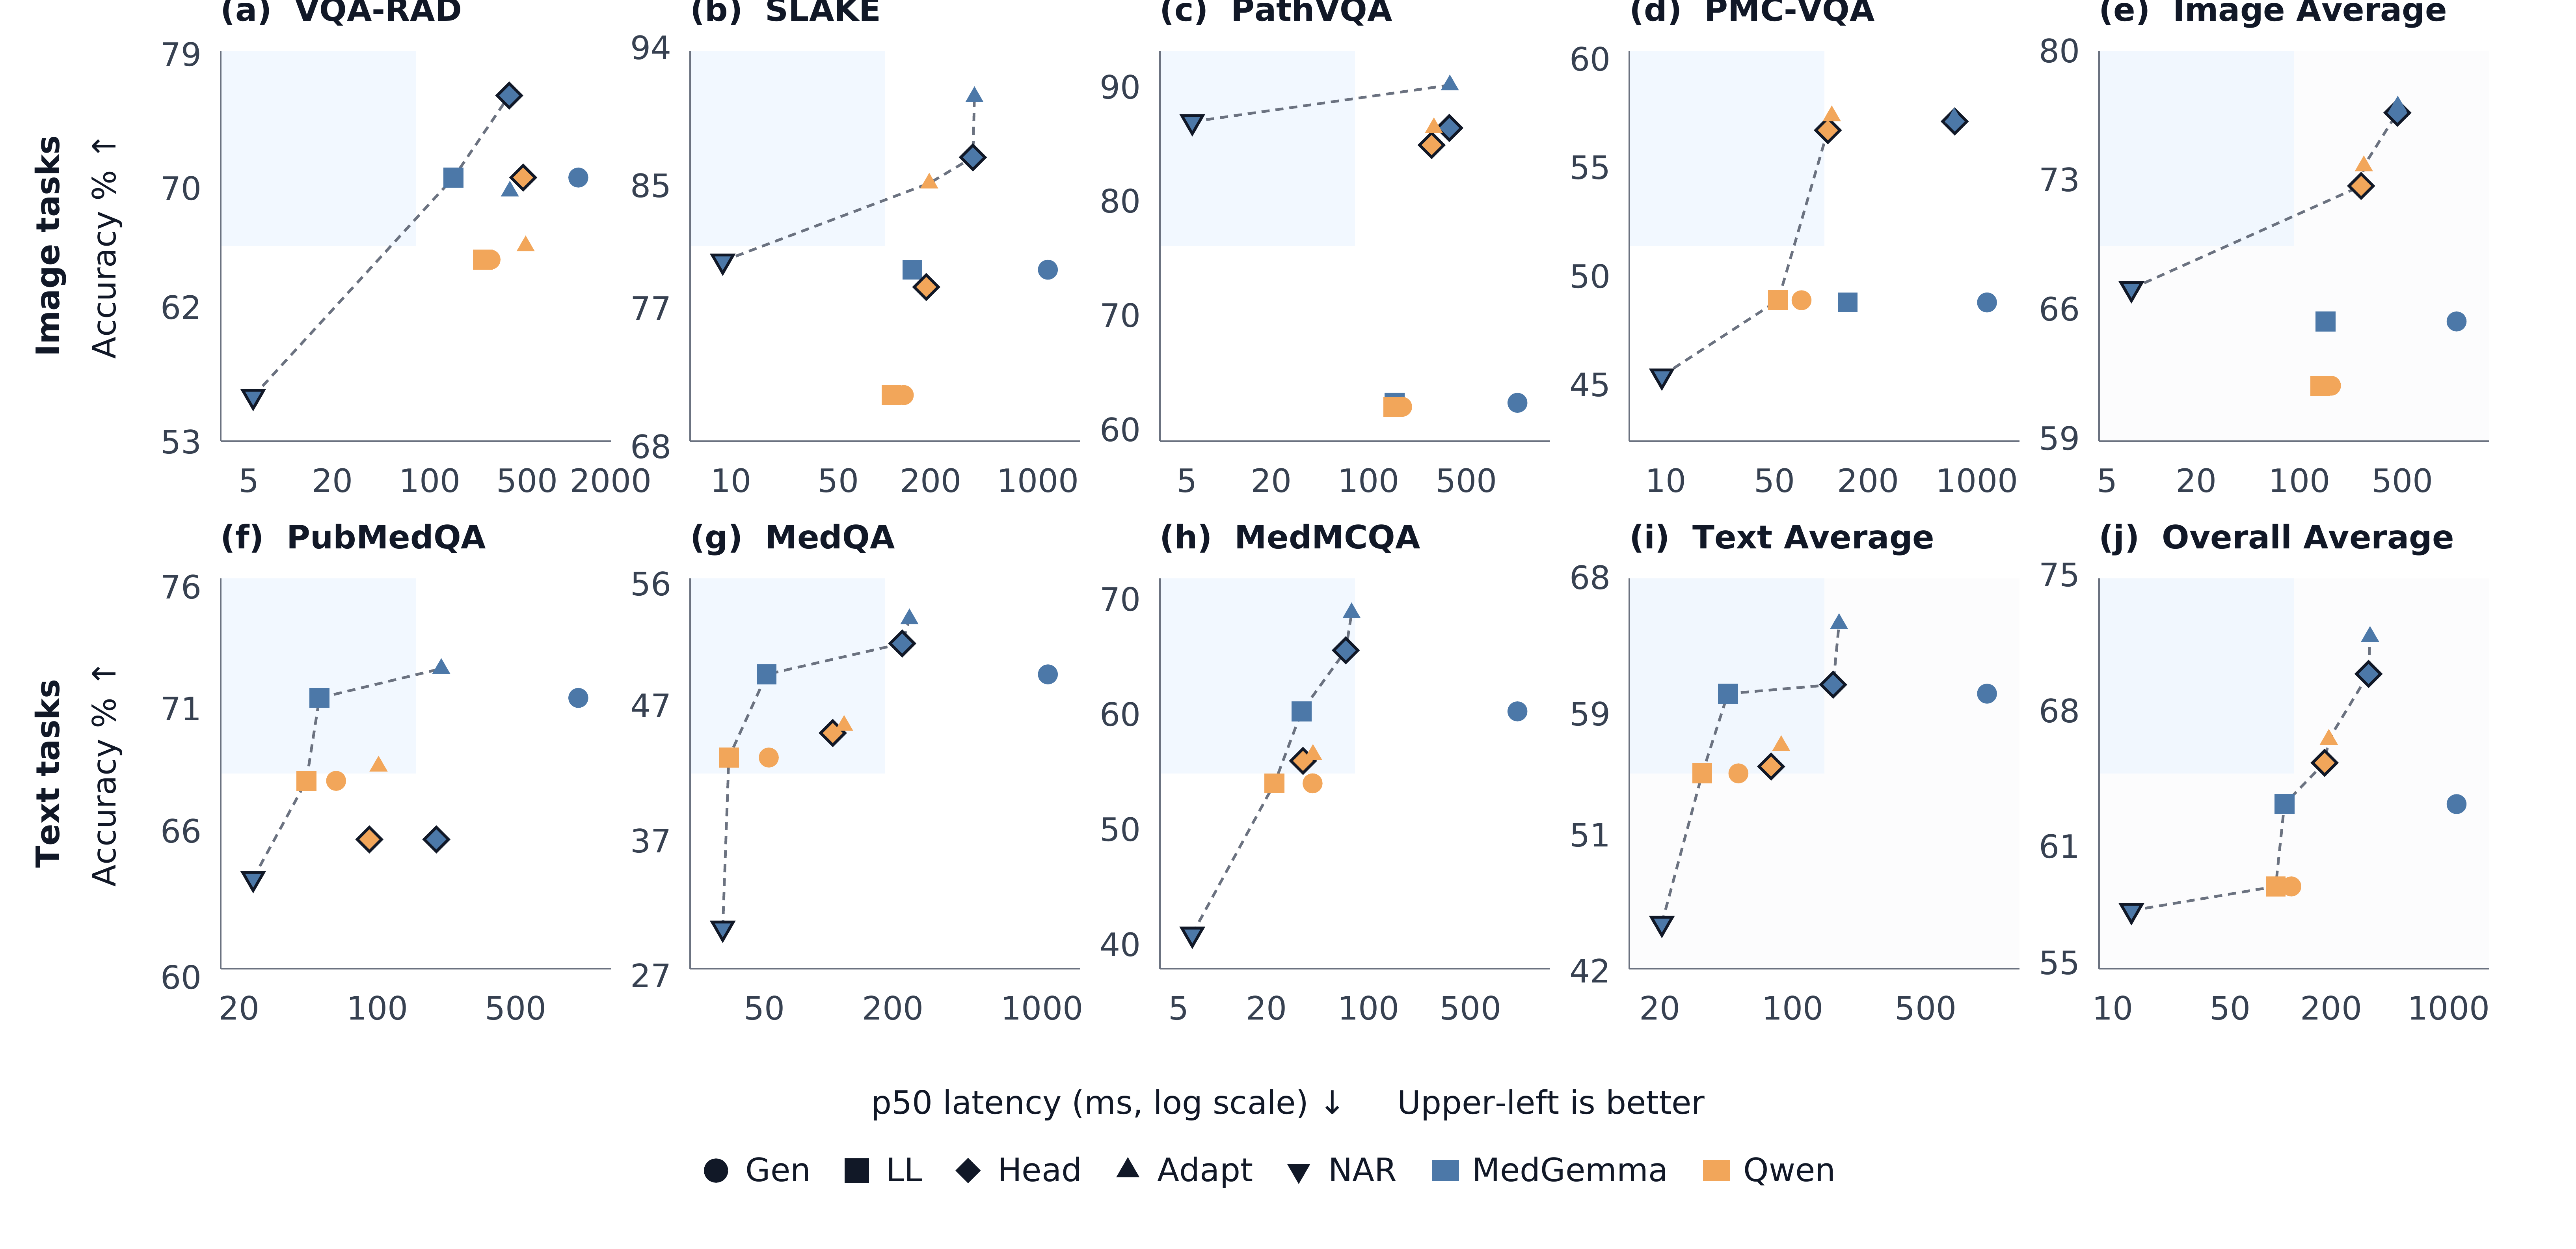

In [1]:
# Install once if needed:
# %pip install reportlab
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "analysis/notebook_results_b.py").is_file())
OUTDIR = ROOT / "analysis/figures_new"
OUTDIR.mkdir(parents=True, exist_ok=True)
FONT_DIR = None

from pathlib import Path
import csv, importlib.util, shutil, subprocess, math
from reportlab.graphics.shapes import Drawing, Group, String, Rect, PolyLine
from reportlab.graphics.charts.lineplots import LinePlot
from reportlab.graphics.widgets.markers import makeMarker
from reportlab.graphics import renderPDF, renderSVG
from reportlab.lib.colors import HexColor, Color
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

METHODS = ['MedGemma-AR', 'MedGemma-LL', 'MedGemma-Head', 'MedGemma-Adapt', 'Laya-Med', 'Qwen-AR', 'Qwen-LL', 'Qwen-Head', 'Qwen-Adapt']
# Read measured results; the rendering code below is unchanged.
import sys
_results_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "analysis" / "notebook_results.py").is_file()
)
if str(_results_root / "analysis") not in sys.path:
    sys.path.insert(0, str(_results_root / "analysis"))
from notebook_results_b import load_paper_results
_saved_results = load_paper_results()
ACCURACY = _saved_results["accuracy"]
LATENCY = _saved_results["latency"]
DATASETS = ['VQA-RAD','SLAKE','PathVQA','PMC-VQA','Image Average','PubMedQA','MedQA','MedMCQA','Text Average','Overall Average']

def locate_fonts(explicit=None):
    candidates = [Path(explicit)] if explicit else []
    candidates += [Path('/usr/share/fonts/truetype/dejavu'), Path('/usr/share/fonts/dejavu'), Path('/usr/local/share/fonts'), Path.home()/'.fonts', Path.home()/'Library/Fonts']
    spec=importlib.util.find_spec('matplotlib')
    if spec and spec.origin: candidates.append(Path(spec.origin).parent/'mpl-data/fonts/ttf')
    for folder in candidates:
        if all((folder/f).exists() for f in ['DejaVuSans.ttf','DejaVuSans-Bold.ttf']): return folder
    raise RuntimeError('DejaVu Sans not found; set FONT_DIR.')

def pareto(points):
    out=[]
    for i,p in enumerate(points):
        _,lat,acc=p
        dominated=any(j!=i and q[1]<=lat and q[2]>=acc and (q[1]<lat or q[2]>acc) for j,q in enumerate(points))
        if not dominated: out.append(p)
    return sorted(out,key=lambda z:z[1])

def generate(outdir=OUTDIR, font_dir=FONT_DIR, make_png=True):
    outdir=Path(outdir); outdir.mkdir(parents=True,exist_ok=True)
    fd=locate_fonts(font_dir)
    for name,fn in [('DejaVuSans','DejaVuSans.ttf'),('DejaVuSans-Bold','DejaVuSans-Bold.ttf')]:
        try: pdfmetrics.registerFont(TTFont(name,str(fd/fn)))
        except: pass
    colors=['#4C78A8'] * 5 + ['#F2A65A'] * 4
    kinds=['FilledCircle','FilledSquare','FilledDiamond','FilledTriangle','FilledTriangle','FilledCircle','FilledSquare','FilledDiamond','FilledTriangle']
    angles=[0,0,0,0,180,0,0,0,0]
    ink=HexColor('#111827'); gray=HexColor('#374151'); spine=HexColor('#6B7280')
    W,H=957.267906,463.868812; d=Drawing(W,H)
    def txt(x,y,t,size=12,bold=False,align='start',color=ink):
        d.add(String(x,y,t,fontName='DejaVuSans-Bold' if bold else 'DejaVuSans',fontSize=size,fillColor=color,textAnchor=align))
    def marker(j,size=None):
        m=makeMarker(kinds[j]); m.size=size or [7,7,9,7,9,7,7,9,7][j]; m.angle=angles[j]
        m.fillColor=HexColor(colors[j]); m.strokeColor=ink if j in (2,4,7) else HexColor(colors[j]); m.strokeWidth=1.05 if j in (2,4,7) else .4; return m
    rows=[]; placements=[]
    for ds in DATASETS:
        for m in METHODS:
            a=ACCURACY[ds].get(m); l=LATENCY[ds].get(m)
            rows.append(dict(dataset=ds,method=m,accuracy=a,latency=l))
    for i,name in enumerate(DATASETS):
        col=i%5; row=i//5; x=82+col*174.5; y=300 if row==0 else 104; w=145; h=145
        if 'Average' in name: d.add(Rect(x,y,w,h,fillColor=HexColor('#FCFCFD'),strokeColor=None))
        pts=[(m,float(LATENCY[name][m]),float(ACCURACY[name][m])) for m in METHODS if ACCURACY[name].get(m) is not None and LATENCY[name].get(m) is not None]
        logs=[math.log10(p[1]) for p in pts]; ys=[p[2] for p in pts]
        xmin,xmax=min(logs),max(logs); padx=max(.12,(xmax-xmin)*.10); xmin-=padx; xmax+=padx
        ymin,ymax=min(ys),max(ys); pady=max(3,(ymax-ymin)*.09); ymin=max(0,ymin-pady); ymax=min(100,ymax+pady)
        if ymax-ymin<16: c=(ymax+ymin)/2; ymin=max(0,c-8); ymax=min(100,c+8)
        # Same pale-blue cue as ECE-NLL, adapted to the desired upper-left direction.
        d.add(Rect(x,y+h/2,w/2,h/2,fillColor=Color(238/255,246/255,1,alpha=.75),strokeColor=None))
        # Pareto frontier in the same restrained gray dashed visual language.
        fr=pareto(pts)
        if len(fr)>=2:
            xy=[]
            for _,lat,acc in fr:
                px=x+(math.log10(lat)-xmin)/(xmax-xmin)*w; py=y+(acc-ymin)/(ymax-ymin)*h; xy += [px,py]
            pl=PolyLine(xy,strokeColor=spine,strokeWidth=1.0); pl.strokeDashArray=[3,2.2]; d.add(pl)
        plot=LinePlot(); plot.x=x; plot.y=y; plot.width=w; plot.height=h
        inds=[]; data=[]
        for j,m in enumerate(METHODS):
            a=ACCURACY[name].get(m); lat=LATENCY[name].get(m)
            if a is None or lat is None: continue
            inds.append(j); lx=math.log10(lat); data.append([(lx,a)])
            placements.append(dict(dataset=name,method=m,accuracy=a,latency=lat))
        plot.data=data
        for k,j in enumerate(inds): plot.lines[k].strokeColor=None; plot.lines[k].strokeWidth=0; plot.lines[k].symbol=marker(j)
        # x ticks at clean latency values inside each panel range
        cand=[5,10,20,50,100,200,500,1000,2000]
        xt=[math.log10(v) for v in cand if xmin<=math.log10(v)<=xmax]
        if len(xt)>4: xt=xt[::2]
        # yt0=math.ceil(ymin/10)*10; yt1=math.floor(ymax/10)*10; yt=list(range(int(yt0),int(yt1)+1,10)) or [round(ymin),round(ymax)]
        # ------------------------------------------------------------
        # Y ticks: minimum 4, maximum 6 labels per subplot
        # ------------------------------------------------------------

        span = ymax - ymin

        # Choose a clean step based on the visible y-range
        if span <= 20:
            ystep = 5
        elif span <= 35:
            ystep = 10
        elif span <= 55:
            ystep = 10
        elif span <= 75:
            ystep = 15
        else:
            ystep = 20

        yt0 = math.ceil(ymin / ystep) * ystep
        yt1 = math.floor(ymax / ystep) * ystep

        yt = []
        v = yt0

        while v <= yt1 + 1e-9:
            yt.append(v)
            v += ystep

        # If fewer than 4 ticks, generate 4 evenly spaced ticks
        if len(yt) < 4:
            yt = [
                ymin + i * (ymax - ymin) / 3
                for i in range(4)
            ]

            # Round to clean integer values
            yt = [round(v) for v in yt]

        # If more than 6 ticks, reduce to 6
        if len(yt) > 6:
            indices = [
                round(i * (len(yt) - 1) / 5)
                for i in range(6)
            ]
            yt = [yt[i] for i in indices]
        plot.xValueAxis.valueMin=xmin; plot.xValueAxis.valueMax=xmax; plot.xValueAxis.valueSteps=xt; plot.xValueAxis.forceZero=False
        plot.yValueAxis.valueMin=ymin; plot.yValueAxis.valueMax=ymax; plot.yValueAxis.valueSteps=yt; plot.yValueAxis.forceZero=False
        for axis in (plot.xValueAxis,plot.yValueAxis):
            axis.visibleGrid=False; axis.strokeColor=spine; axis.strokeWidth=.6; axis.visibleTicks=False; axis.labels.fontName='DejaVuSans'; axis.labels.fontSize=12; axis.labels.fillColor=gray
        plot.xValueAxis.labelTextFormat=lambda v: f'{10**v:g}'; plot.yValueAxis.labelTextFormat=lambda v:f'{v:g}'
        plot.xValueAxis.labels.dy=-7; plot.xValueAxis.labels.boxAnchor='n'; plot.yValueAxis.labels.dx=-7; plot.yValueAxis.labels.boxAnchor='e'
        plot.xValueAxis.joinAxisMode='bottom'; plot.yValueAxis.joinAxisMode='left'; d.add(plot)
        title=name
        txt(x,y+h+11,f'({chr(97+i)})  {title}',12,True)
    for label,cy in [('Image tasks',372.5),('Text tasks',176.5)]:
        g=Group(); g.add(String(0,0,label,fontName='DejaVuSans-Bold',fontSize=12,fillColor=ink,textAnchor='middle')); g.translate(22,cy); g.rotate(90); d.add(g)
        g=Group(); g.add(String(0,0,'Accuracy % ↑',fontName='DejaVuSans',fontSize=12,fillColor=ink,textAnchor='middle')); g.translate(43,cy); g.rotate(90); d.add(g)
    txt(W/2,50,'p50 latency (ms, log scale) ↓     Upper-left is better',12,align='middle')
    # Formulation shapes are neutral; color identifies the backbone.
    entries = [('Gen', 0), ('LL', 1), ('Head', 2), ('Adapt', 3), ('NAR', 4),
               ('MedGemma', None), ('Qwen', None)]
    widths = [28 + pdfmetrics.stringWidth(label, 'DejaVuSans', 12) for label, _ in entries]
    xx = (W - sum(widths)) / 2
    for (label, j), width in zip(entries, widths):
        if j is None:
            color = HexColor('#4C78A8' if label == 'MedGemma' else '#F2A65A')
            d.add(Rect(xx, 25, 10, 8, fillColor=color, strokeColor=None))
        else:
            q = marker(j, 8)
            q.fillColor = ink
            q.strokeColor = ink
            q.strokeWidth = 1
            q.x = xx + 4; q.y = 29; d.add(q)
        txt(xx + 15, 25, label, 12)
        xx += width

    assert len(placements)==90
    stem=outdir/'accuracy_latency_pareto_ece_nll_style'
    # Uniform physical scaling: 4.5 x 4.5 inches per data panel.
    panel_scale = (4.5 * 72) / 145
    d.scale(panel_scale, panel_scale)
    d.width *= panel_scale
    d.height *= panel_scale
    renderPDF.drawToFile(d,str(stem.with_suffix('.pdf')),title='Accuracy-latency Pareto quality')
    renderSVG.drawToFile(d,str(stem.with_suffix('.svg')))
    with (outdir/'accuracy_latency_pareto_ece_nll_style_data.csv').open('w',newline='') as f:
        wr=csv.DictWriter(f,fieldnames=['dataset','method','accuracy','latency']); wr.writeheader(); wr.writerows(rows)
    if make_png:
        poppler=shutil.which('pdftoppm')
        if poppler: subprocess.run([poppler,'-r','220','-png','-singlefile',str(stem.with_suffix('.pdf')),str(stem)],check=True)
    print(f'Saved 10 panels with {len(placements)} available accuracy/latency pairs to {outdir}')
    return stem

stem = generate()

from IPython.display import Image, display
png = stem.with_suffix('.png')
if png.exists(): display(Image(filename=str(png)))
else: print('PNG not available; PDF/SVG were still created.')

# Heatmap: accuracy and p50 column blocks
Each block orders methods from Jev to NAR, with separators after Jev, before Qwen, and before NAR. Model-family headers span their variant columns. Values use the same readable font size in both blocks, with the existing performance colors. Export at native width or on a landscape page to preserve readability.


Wrote: /home/razaimam/Documents/Projects/Jevify/analysis/figures_new/medical_sysone_table.tex


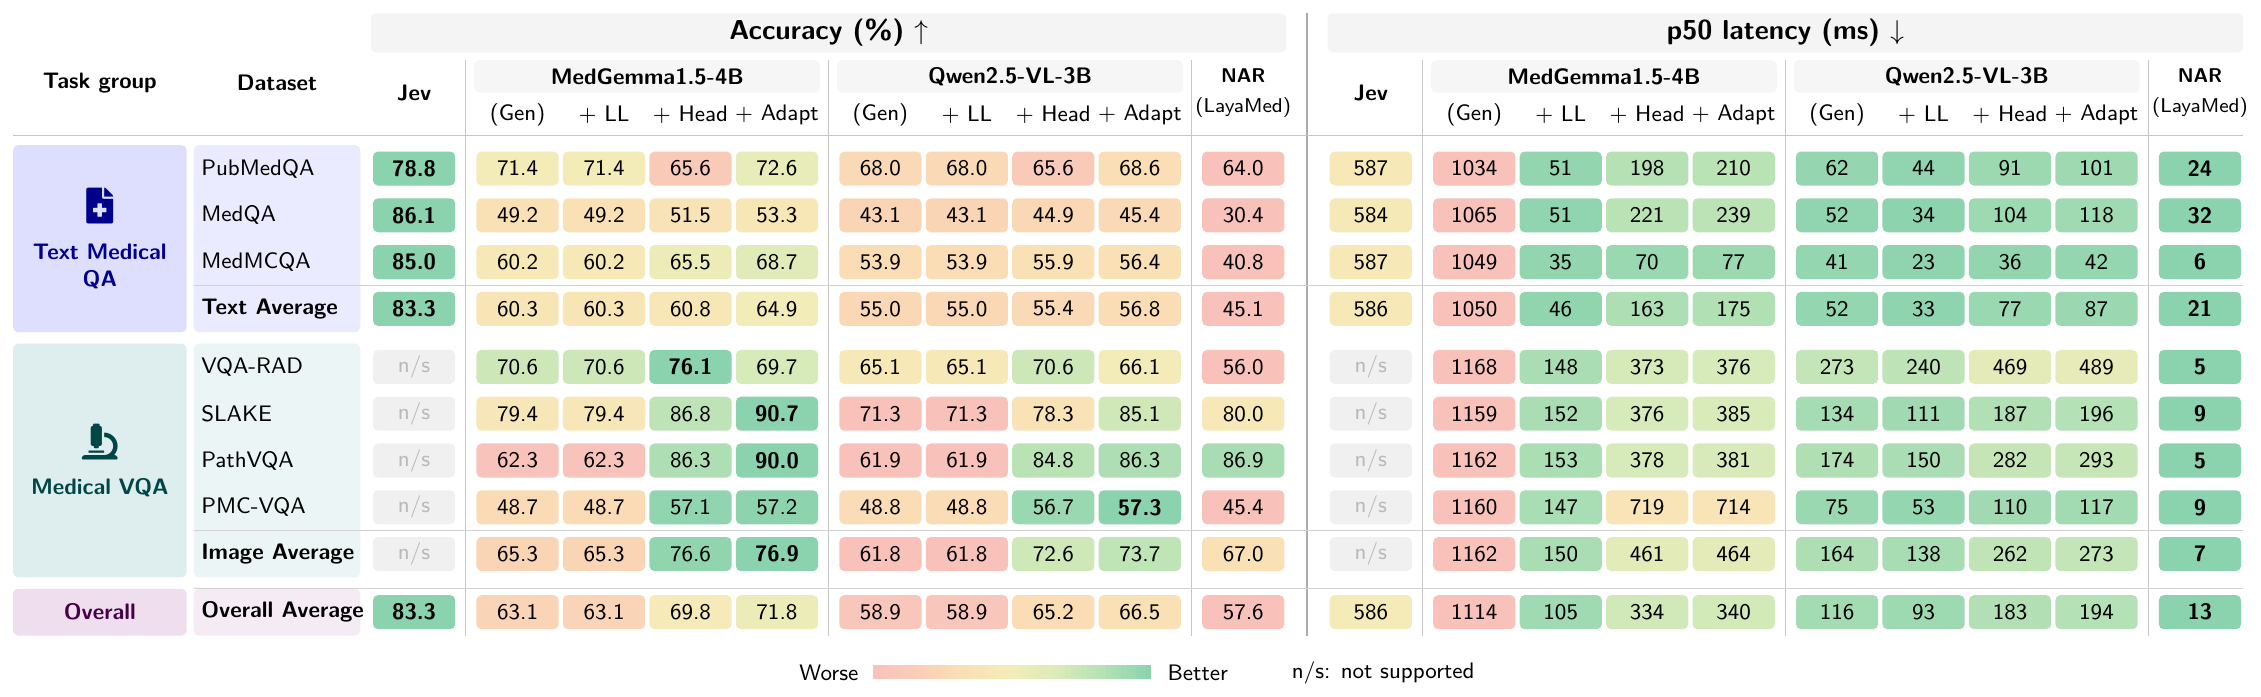

In [2]:
#!/usr/bin/env python3
"""Generate side-by-side accuracy and p50 TikZ blocks with ten methods each.
Colors retain per-dataset normalization: higher accuracy and lower latency are greener.
The table uses fixed readable font sizes; include at native size on a wide page.
Requires tikz, xcolor and fontawesome5. Optional Tectonic renders a PDF/PNG preview.
"""

from __future__ import annotations

from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple


# ============================================================
# Configuration
# ============================================================

from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "analysis/notebook_results_b.py").is_file())
OUTDIR = ROOT / "analysis/figures_new"
OUTDIR.mkdir(parents=True, exist_ok=True)

OUTPUT = OUTDIR / "medical_sysone_table.tex"


# ============================================================
# Methods
# ============================================================

METHODS = ['Jev', 'MedGemma-AR', 'MedGemma-LL', 'MedGemma-Head', 'MedGemma-Adapt', 'Qwen-AR', 'Qwen-LL', 'Qwen-Head', 'Qwen-Adapt', 'Laya-Med']


METHOD_DISPLAY = {'Jev': 'Jev', 'MedGemma-AR': 'MedGemma\\\\1.5-4B (Gen)', 'MedGemma-LL': '+ LL', 'MedGemma-Head': '+ Head', 'MedGemma-Adapt': '+ Adapt', 'Qwen-AR': 'Qwen2.5\\\\VL-3B (Gen)', 'Qwen-LL': '+ LL', 'Qwen-Head': '+ Head', 'Qwen-Adapt': '+ Adapt', 'Laya-Med': 'NAR\\\\(LayaMed)'}


# ============================================================
# Dataset groups
# ============================================================

GROUPS = [
    (
        "Text Medical QA",
        [
            "PubMedQA",
            "MedQA",
            "MedMCQA",
            "Text Average",
        ],
    ),
    (
        "Medical VQA",
        [
            "VQA-RAD",
            "SLAKE",
            "PathVQA",
            "PMC-VQA",
            "Image Average",
        ],
    ),
    (
        "Overall",
        [
            "Overall Average",
        ],
    ),
]


# ============================================================
# Accuracy (%)
# ============================================================

# Read measured results; the rendering code below is unchanged.
import sys
_results_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "analysis" / "notebook_results.py").is_file()
)
if str(_results_root / "analysis") not in sys.path:
    sys.path.insert(0, str(_results_root / "analysis"))
from notebook_results_b import load_paper_results
_saved_results = load_paper_results()
ACCURACY = {dataset: [values[method] for method in METHODS]
            for dataset, values in _saved_results["accuracy"].items()}


# ============================================================
# p50 latency (ms)
# ============================================================

LATENCY = {dataset: [values[method] for method in METHODS]
            for dataset, values in _saved_results["latency"].items()}


# ============================================================
# Layout
# ============================================================

GROUP_X0 = 0.00
GROUP_W = 2.45

DATASET_X0 = 2.55
DATASET_W = 2.35

METHOD_X0 = 5.05

METHOD_W = 1.27
METHOD_GAP = 0.08

HEADER_H = 1.20

ROW_H = 0.66
GROUP_GAP = 0.16

# One metric per cell, with the same physical text size in both blocks.
CELL_W = 1.16
CELL_H = 0.48
CELL_GAP = 0.055

BOTTOM_LEGEND_GAP = 0.55


# ============================================================
# Group colors
# ============================================================

GROUP_COLORS = {
    "Text Medical QA": "blue",
    "Medical VQA": "teal",
    "Overall": "violet",
}


# ============================================================
# Performance palette
#
# Same semantic palette for both metrics:
#
#   red    = worse
#   yellow = intermediate
#   green  = better
#
# Accuracy:
#   higher -> greener
#
# Latency:
#   lower -> greener
# ============================================================

ACC_COLORS = [
    (248, 194, 187),   # worst
    (249, 207, 183),
    (250, 224, 181),
    (244, 236, 184),
    (218, 235, 185),
    (181, 225, 181),
    (139, 211, 174),   # best
]


# ============================================================
# Helpers
# ============================================================

def escape_tex(text: str) -> str:
    """Minimal TeX escaping for generated labels."""

    return (
        text
        .replace("&", r"\&")
        .replace("%", r"\%")
        .replace("_", r"\_")
    )


def lighten_rgb(
    rgb: Tuple[int, int, int],
    amount: float = 0.35,
) -> Tuple[int, int, int]:
    """
    Blend an RGB color toward white.

    amount = 0 -> original
    amount = 1 -> white
    """

    return tuple(
        round(
            channel
            + (255 - channel) * amount
        )
        for channel in rgb
    )


def interpolate_rgb(
    palette: Sequence[Tuple[int, int, int]],
    t: float,
) -> Tuple[int, int, int]:
    """
    Piecewise-linear interpolation through an RGB palette.

    Parameters
    ----------
    palette
        Ordered RGB colors from worst to best.

    t
        Scalar in [0, 1].
    """

    t = max(
        0.0,
        min(1.0, t),
    )

    if len(palette) == 1:
        return palette[0]

    position = (
        t
        * (len(palette) - 1)
    )

    index = int(position)

    if index >= len(palette) - 1:
        return palette[-1]

    fraction = position - index

    first = palette[index]
    second = palette[index + 1]

    return tuple(
        round(
            first[channel]
            + fraction
            * (
                second[channel]
                - first[channel]
            )
        )
        for channel in range(3)
    )


def rgb_tex(
    rgb: Tuple[int, int, int],
) -> str:
    """Convert RGB tuple to xcolor/TikZ inline RGB syntax."""

    r, g, b = rgb

    return (
        f"{{rgb,255:red,{r};"
        f"green,{g};"
        f"blue,{b}}}"
    )


def normalize(
    value: float,
    lo: float,
    hi: float,
) -> float:
    """Normalize to [0,1]."""

    if hi == lo:
        return 0.5

    return (
        (value - lo)
        / (hi - lo)
    )


def valid_values(
    values: Sequence[Optional[float]],
) -> List[float]:
    """Return all non-missing numeric values."""

    return [
        float(value)
        for value in values
        if value is not None
    ]


def best_indices(
    values: Sequence[Optional[float]],
    higher_is_better: bool,
) -> set[int]:
    """
    Return all indices tied for the best available value.
    """

    valid = valid_values(values)

    if not valid:
        return set()

    if higher_is_better:
        target = max(valid)
    else:
        target = min(valid)

    return {
        index
        for index, value in enumerate(values)
        if (
            value is not None
            and abs(
                float(value)
                - target
            ) < 1e-9
        )
    }


def format_accuracy(
    value: float,
) -> str:
    """Accuracy is always shown with one decimal place."""

    return f"{value:.1f}"


def format_latency(
    value: float,
) -> str:
    """Latency is shown as integer milliseconds."""

    return f"{value:.0f}"


def method_x(
    index: int,
) -> float:
    """Horizontal center of a method column."""

    return (
        METHOD_X0
        + index
        * (
            METHOD_W
            + METHOD_GAP
        )
        + METHOD_W / 2
    )


def row_center(
    y_top: float,
) -> float:
    """Vertical center of a dataset row."""

    return (
        y_top
        - ROW_H / 2
    )


# ============================================================
# TikZ heatmap cell
# ============================================================

def heat_cell(
    x: float,
    y: float,
    value: Optional[float],
    color_value: Optional[float],
    color_values: Sequence[Optional[float]],
    metric: str,
    bold: bool = False,
) -> str:
    """
    Generate one rounded TikZ heatmap mini-cell.

    Accuracy
    --------
    Higher values -> greener.

    Latency
    -------
    Lower values -> greener.
    Latency cells are lightened and use smaller gray text.
    """

    # --------------------------------------------------------
    # Unsupported / unavailable
    # --------------------------------------------------------

    if value is None:

        return (
            rf"\node["
            rf"fill=gray!12,"
            rf"rounded corners=2pt,"
            rf"minimum width={CELL_W:.3f}cm,"
            rf"minimum height={CELL_H:.3f}cm,"
            rf"inner sep=0pt,"
            rf"text=gray!55"
            rf"] "
            rf"at ({x:.3f},{y:.3f}) "
            rf"{{n/s}};"
        )

    # --------------------------------------------------------
    # Row-wise normalization
    # --------------------------------------------------------

    valid = valid_values(
        color_values
    )

    lo = min(valid)
    hi = max(valid)

    if metric == "accuracy":

        # Higher accuracy = better.
        score = normalize(
            float(color_value),
            lo,
            hi,
        )

    elif metric == "latency":

        # Lower latency = better.
        score = (
            1.0
            - normalize(
                float(color_value),
                lo,
                hi,
            )
        )

    else:

        raise ValueError(
            f"Unknown metric: {metric}"
        )

    # --------------------------------------------------------
    # Map quality -> color
    # --------------------------------------------------------

    rgb = interpolate_rgb(
        ACC_COLORS,
        score,
    )

    # Latency uses same semantics,
    # but is visually secondary.
    # if metric == "latency":

    #     rgb = lighten_rgb(
    #         rgb,
    #         amount=0.35,
    #     )

    # --------------------------------------------------------
    # Text formatting
    # --------------------------------------------------------

    if metric == "accuracy":

        text = format_accuracy(
            float(value)
        )

        if bold:
            text = (
                rf"\textbf{{{text}}}"
            )

        text_style = (
            r"text=black,"
            r"font=\normalfont\sffamily\mdseries\fontsize{9}{11}\selectfont"
        )

    else:

        text = format_latency(
            float(value)
        )

        if bold:
            text = (
                rf"\textbf{{{text}}}"
            )

        text_style = (
            r"text=black,"
            r"font=\normalfont\sffamily\mdseries\fontsize{9}{11}\selectfont"
        )

    # --------------------------------------------------------
    # Node
    # --------------------------------------------------------

    return (
        rf"\node["
        rf"fill={rgb_tex(rgb)},"
        rf"rounded corners=2pt,"
        rf"minimum width={CELL_W:.3f}cm,"
        rf"minimum height={CELL_H:.3f}cm,"
        rf"inner sep=0pt,"
        rf"{text_style}"
        rf"] "
        rf"at ({x:.3f},{y:.3f}) "
        rf"{{{text}}};"
    )


# ============================================================
# Build TikZ
# ============================================================

def build_tikz() -> str:
    """Two metric blocks, each with identical method order and family boundaries."""
    # Preserve readable physical font sizes; do not shrink the table to text width.
    column_width = 1.22
    family_gap = .24
    block_gap = .58
    boundaries = (1, 5, 9)  # after Jev; before Qwen; before NAR
    starts = []
    cursor = METHOD_X0
    for i in range(len(METHODS)):
        if i in boundaries:
            cursor += family_gap
        starts.append(cursor)
        cursor += column_width
    block_width = cursor - METHOD_X0
    block_starts = [METHOD_X0, cursor + block_gap]
    table_right = block_starts[1] + block_width
    data_top = -1.86
    table_bottom = data_top - sum(len(ds) for _, ds in GROUPS) * ROW_H - (len(GROUPS) - 1) * GROUP_GAP
    lines = [r"\begin{tikzpicture}[x=1cm,y=1cm,font=\sffamily\fontsize{9}{11}\selectfont]"]

    def node(x, y, text, options=""):
        lines.append(rf"\node[align=center,inner sep=0pt{',' + options if options else ''}] at ({x:.3f},{y:.3f}) {{{text}}};")

    def rect(left, top, right, bottom, color):
        lines.append(rf"\fill[{color},rounded corners=2pt] ({left:.3f},{top:.3f}) rectangle ({right:.3f},{bottom:.3f});")

    def rule(x, top, bottom, strong=False):
        style = "gray!65,line width=.7pt" if strong else "gray!45,line width=.45pt"
        lines.append(rf"\draw[{style}] ({x:.3f},{top:.3f}) -- ({x:.3f},{bottom:.3f});")

    node(GROUP_X0 + GROUP_W / 2, -.98, r"\textbf{Task group}")
    node(DATASET_X0 + DATASET_W / 2, -.98, r"\textbf{Dataset}")
    centers_by_metric = {}
    for metric, left, title in zip(("accuracy", "latency"), block_starts,
                                   (r"Accuracy (\%) $\uparrow$", r"p50 latency (ms) $\downarrow$")):
        shift = left - METHOD_X0
        centers = [x + shift + column_width / 2 for x in starts]
        centers_by_metric[metric] = centers
        rect(left, 0, left + block_width, -.55, "gray!9")
        node(left + block_width / 2, -.275, rf"\textbf{{{title}}}", r"font=\sffamily\fontsize{11}{13}\selectfont")
        # Model names span their four variant columns, avoiding tiny or wrapped names.
        for first, last, label in [(1, 4, "MedGemma1.5-4B"), (5, 8, "Qwen2.5-VL-3B")]:
            rect(starts[first] + shift, -.66, starts[last] + shift + column_width, -1.12, "gray!7")
            node((centers[first] + centers[last]) / 2, -.89, rf"\textbf{{{label}}}")
            for index, variant in zip(range(first, last + 1), ["(Gen)", "+ LL", "+ Head", "+ Adapt"]):
                node(centers[index], -1.43, variant)
        node(centers[0], -1.13, r"\textbf{Jev}")
        node(centers[9], -1.13, r"\textbf{NAR}\\[2pt](LayaMed)", r"font=\sffamily\fontsize{8}{10}\selectfont")
        for boundary in boundaries:
            rule(starts[boundary] + shift - family_gap / 2, -.66, table_bottom)
    rule((block_starts[0] + block_width + block_starts[1]) / 2, 0, table_bottom, strong=True)
    lines.append(rf"\draw[gray!45,line width=.45pt] ({GROUP_X0:.3f},-1.73) -- ({table_right:.3f},-1.73);")

    y_top = data_top
    for group_name, datasets in GROUPS:
        group_bottom = y_top - len(datasets) * ROW_H
        group_color = GROUP_COLORS[group_name]
        rect(GROUP_X0, y_top, GROUP_X0 + GROUP_W, group_bottom, f"{group_color}!13")
        rect(DATASET_X0, y_top, DATASET_X0 + DATASET_W, group_bottom, f"{group_color}!8")
        group_content = {
            "Text Medical QA": r"{\Large\faFileMedical}\\[5pt]Text Medical\\QA",
            "Medical VQA": r"{\Large\faMicroscope}\\[5pt]Medical VQA",
            "Overall": "Overall",
        }[group_name]
        node(GROUP_X0 + GROUP_W / 2, (y_top + group_bottom) / 2, group_content,
             rf"text width={GROUP_W-.2:.2f}cm,font=\sffamily\bfseries\fontsize{{9}}{{11}}\selectfont,text={group_color}!55!black")
        for dataset in datasets:
            yc = row_center(y_top)
            is_average = "Average" in dataset
            label = escape_tex(dataset)
            if is_average:
                label = rf"\textbf{{{label}}}"
                lines.append(rf"\draw[gray!35,line width=.35pt] ({DATASET_X0:.3f},{y_top:.3f}) -- ({table_right:.3f},{y_top:.3f});")
            node(DATASET_X0 + .1, yc, label, "anchor=west")
            for metric, source in [("accuracy", ACCURACY), ("latency", LATENCY)]:
                values = source[dataset]
                best = best_indices(values, higher_is_better=metric == "accuracy")
                for index, value in enumerate(values):
                    lines.append(heat_cell(centers_by_metric[metric][index], yc,
                                           value, value, values, metric, index in best))
            y_top -= ROW_H
        y_top -= GROUP_GAP

    # One centered shared key; identical row-wise color semantics in both blocks.
    legend_y = table_bottom - .52
    legend_center = (GROUP_X0 + table_right) / 2 - 1.65
    node(legend_center - 2.15, legend_y, "Worse", "anchor=east")
    for i in range(56):
        x = legend_center - 1.95 + i * .07
        color = rgb_tex(interpolate_rgb(ACC_COLORS, i / 55))
        lines.append(rf"\fill[fill={color}] ({x:.3f},{legend_y-.10:.3f}) rectangle ({x+.072:.3f},{legend_y+.10:.3f});")
    node(legend_center + 2.2, legend_y, "Better", "anchor=west")
    node(legend_center + 5.25, legend_y, "n/s: not supported")
    lines.append(r"\end{tikzpicture}")
    return "\n".join(lines)


def validate_data() -> None:
    """
    Validate that every dataset contains one value per method.
    """

    expected = len(
        METHODS
    )

    datasets = [
        dataset
        for _, group_datasets in GROUPS
        for dataset in group_datasets
    ]

    for dataset in datasets:

        if dataset not in ACCURACY:

            raise KeyError(
                f"Missing accuracy data: "
                f"{dataset}"
            )

        if dataset not in LATENCY:

            raise KeyError(
                f"Missing latency data: "
                f"{dataset}"
            )

        if (
            len(
                ACCURACY[
                    dataset
                ]
            )
            != expected
        ):

            raise ValueError(
                f"{dataset}: "
                f"accuracy has "
                f"{len(ACCURACY[dataset])} "
                f"values; "
                f"expected {expected}"
            )

        if (
            len(
                LATENCY[
                    dataset
                ]
            )
            != expected
        ):

            raise ValueError(
                f"{dataset}: "
                f"latency has "
                f"{len(LATENCY[dataset])} "
                f"values; "
                f"expected {expected}"
            )


# ============================================================
# Main
# ============================================================

def main() -> None:

    validate_data()

    tikz = build_tikz()

    OUTPUT.write_text(
        tikz,
        encoding="utf-8",
    )

    print(
        f"Wrote: "
        f"{OUTPUT.resolve()}"
    )


if __name__ == "__main__":
    main()

# Optional standalone rendering; the TeX fragment remains directly includable.
import os
import shutil
import subprocess
renderer = os.environ.get("TECTONIC") or shutil.which("tectonic")
if renderer:
    import tempfile
    with tempfile.TemporaryDirectory(prefix="jev-heatmap-") as temp:
        wrapper = Path(temp) / "medical_sysone_table.tex"
        wrapper.write_text(
            r"\documentclass[border=5pt]{standalone}" + "\n"
            + r"\usepackage{tikz,xcolor,fontawesome5}" + "\n"
            + r"\begin{document}" + "\n"
            + OUTPUT.read_text() + "\n" + r"\end{document}", encoding="utf-8")
        compiled = subprocess.run([renderer, "--keep-logs", str(wrapper)], capture_output=True, text=True)
        if compiled.returncode:
            raise RuntimeError("Heatmap rendering failed:\n" + compiled.stdout + compiled.stderr)
        shutil.copy2(wrapper.with_suffix(".pdf"), OUTPUT.with_suffix(".pdf"))
    if shutil.which("pdftoppm"):
        subprocess.run(["pdftoppm", "-r", "180", "-png", "-singlefile",
                        str(OUTPUT.with_suffix(".pdf")), str(OUTPUT.with_suffix(""))], check=True)
        from IPython.display import Image, display
        display(Image(filename=str(OUTPUT.with_suffix(".png"))))
else:
    print("TeX saved. Install Tectonic to also render the standalone PDF/PNG preview.")


# Probabilistic Decision Quality — ECE/NLL
MedGemma and Qwen, without Jev, using the ECE–NLL renderer from `a.ipynb` and the same shared formulation/backbone legend as the Pareto figure.


Saved 10 panels, with all 90 available ECE/NLL pairs, to /home/razaimam/Documents/Projects/Jevify/analysis/figures_new


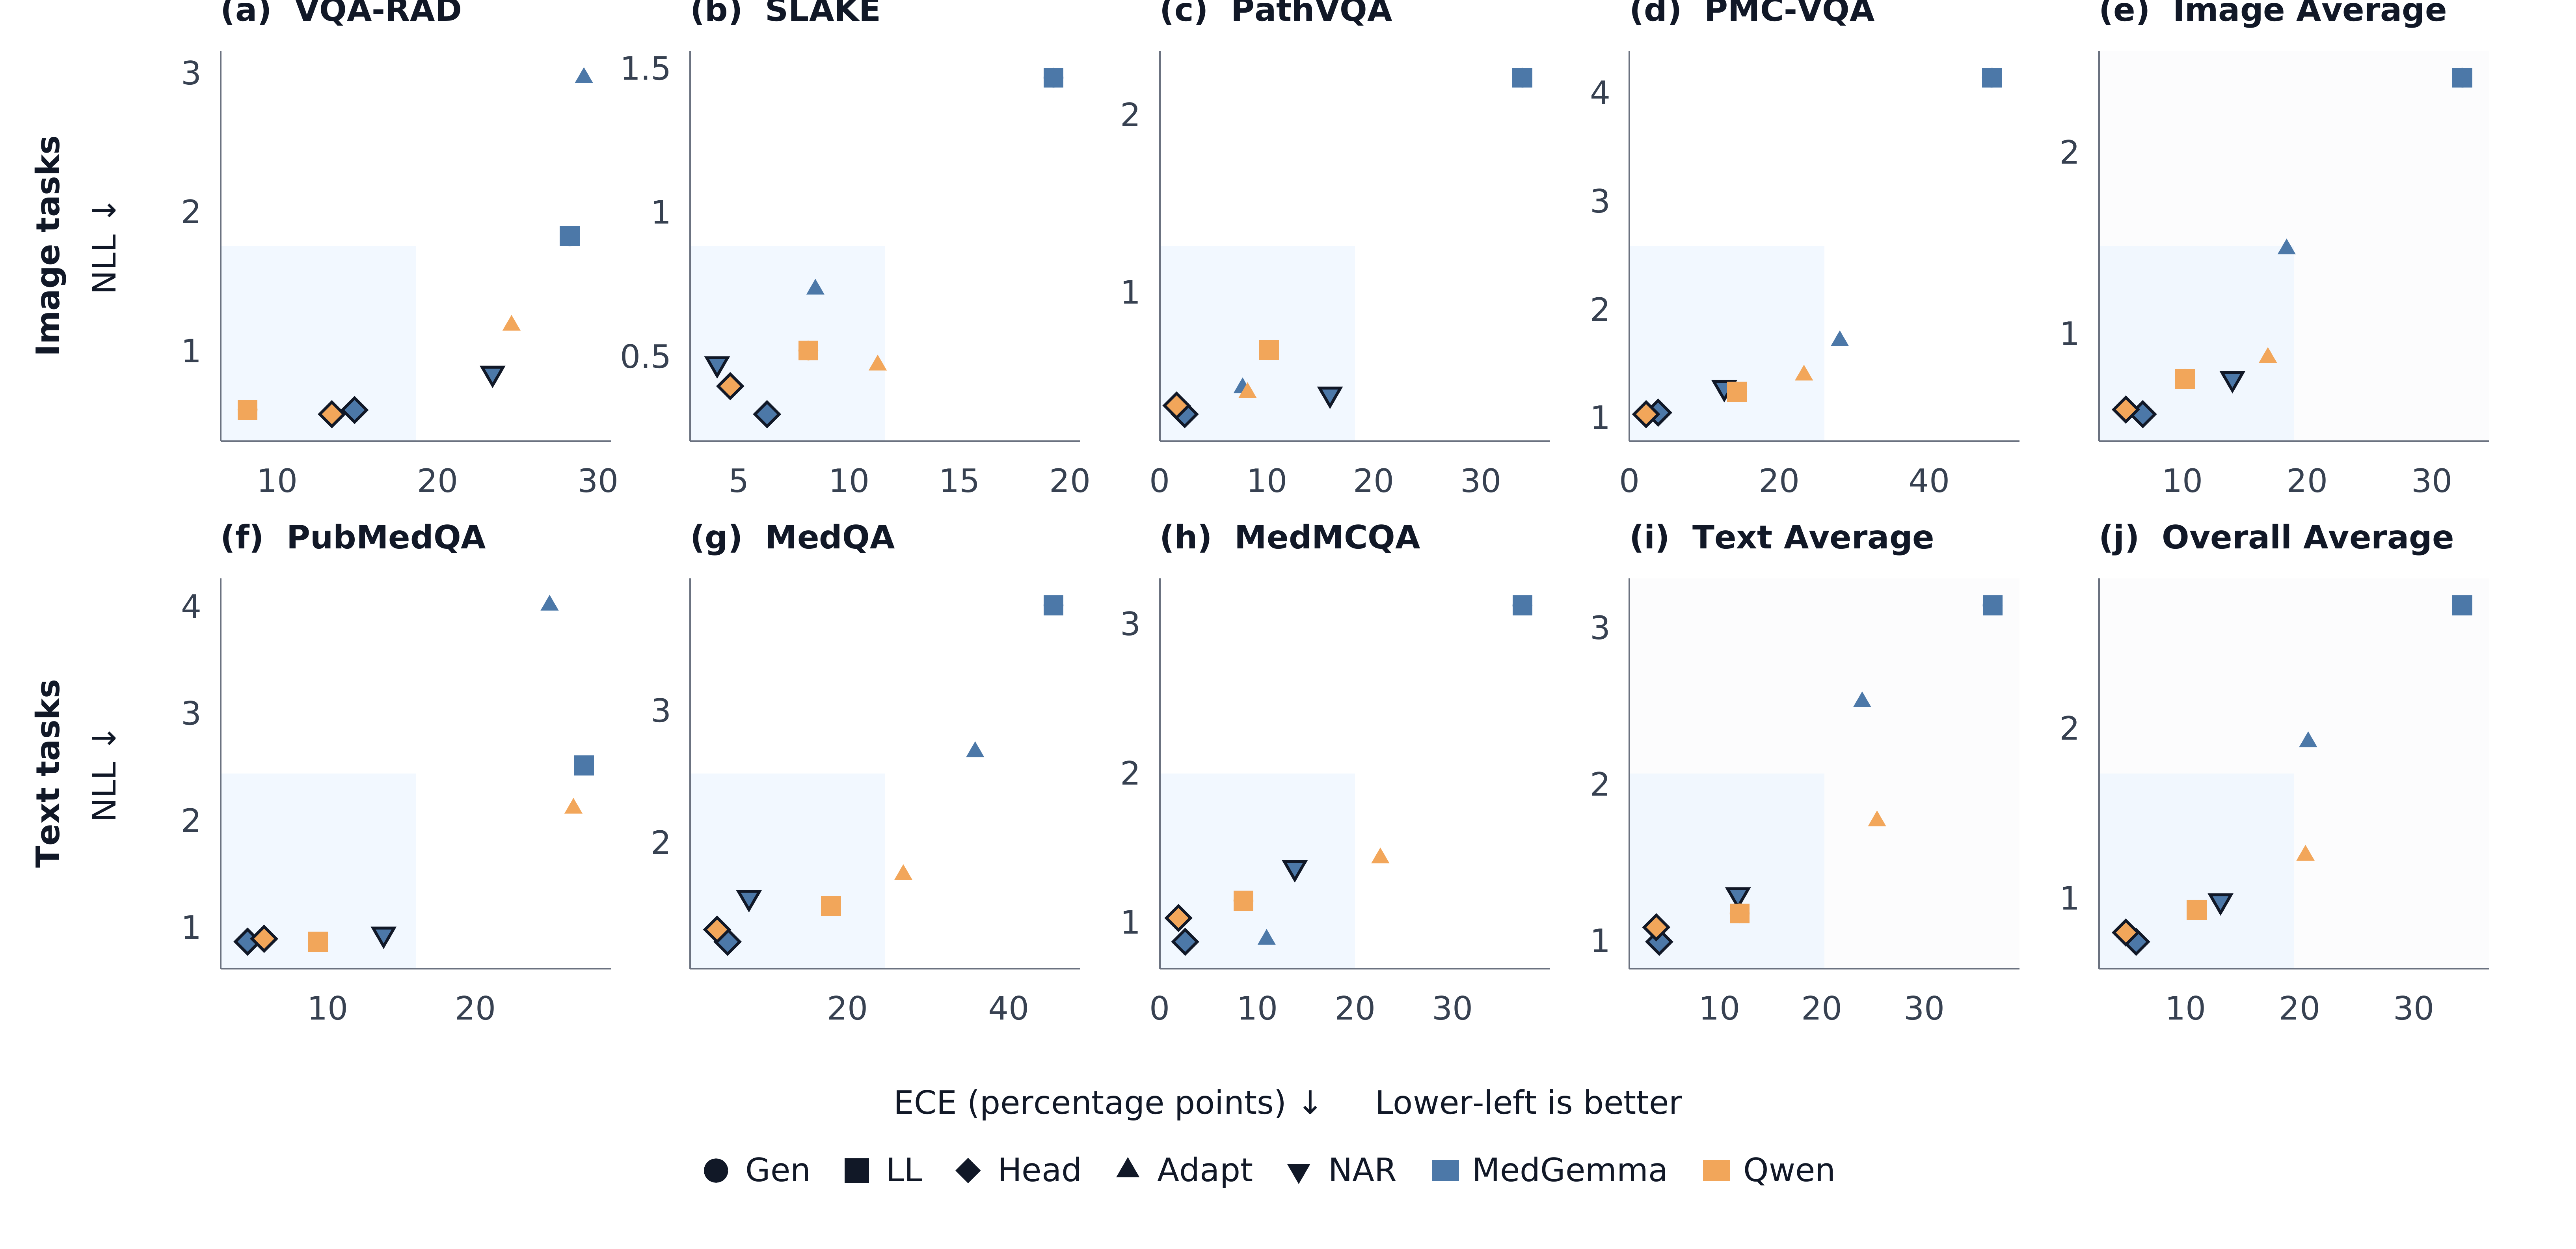

In [3]:
# Install once if needed:
# %pip install reportlab

from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "analysis/notebook_results_b.py").is_file())
OUTDIR = ROOT / "analysis/figures_new"
OUTDIR.mkdir(parents=True, exist_ok=True)
FONT_DIR = None   # e.g. Path('/path/to/DejaVu/fonts'); None = auto-detect
NO_PNG = False

#!/usr/bin/env python3

"""Plot Table 4: probabilistic decision quality, matching the manuscript theme.



Install:  python -m pip install reportlab

Run:      python plot_table4_probabilistic_quality.py --outdir figures

Optional: --font-dir /path/to/DejaVu/fonts --no-png



PDF and SVG are vector outputs. PNG export additionally uses Poppler's pdftoppm

when available; its absence does not prevent PDF/SVG creation.



Data are loaded from results/<model>/results.csv. None means unsupported.

ECE is in percentage points. Both ECE and NLL are lower-is-better.

The blue lower-left quadrant is a directional visual guide, not an acceptance

region or a statistical threshold. Axis ranges differ between panels, as in

the paper's Pareto figure. Averages equally weight supported datasets.

"""

import csv

import importlib.util

import json

import shutil

import subprocess

from pathlib import Path

from reportlab.graphics.shapes import Drawing, Group, String, Rect

from reportlab.graphics.charts.lineplots import LinePlot

from reportlab.graphics.widgets.markers import makeMarker

from reportlab.graphics import renderPDF, renderSVG

from reportlab.lib.colors import HexColor, Color

from reportlab.pdfbase import pdfmetrics

from reportlab.pdfbase.ttfonts import TTFont



METHODS = ['MedGemma-AR', 'MedGemma-LL', 'MedGemma-Head', 'MedGemma-Adapt', 'Laya-Med', 'Qwen-AR', 'Qwen-LL', 'Qwen-Head', 'Qwen-Adapt']

# Read measured results and fit axes; preserve the existing styling and layout.
import sys
_results_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "analysis" / "notebook_results.py").is_file()
)
if str(_results_root / "analysis") not in sys.path:
    sys.path.insert(0, str(_results_root / "analysis"))
from notebook_results_b import load_paper_results, quality_panel_config
_saved_results = load_paper_results()
_quality_groups = {"Text Average": "Text Avg.",
                   "Image Average": "Image Avg.", "Overall Average": "Overall Avg."}
DATA = {
    _quality_groups.get(dataset, dataset): [
        [_saved_results["ece"][dataset][method], _saved_results["nll"][dataset][method]]
        for method in METHODS
    ]
    for dataset in _saved_results["ece"]
}



def locate_fonts(explicit=None):

    candidates = [Path(explicit)] if explicit else []

    candidates += [Path.cwd() / 'fonts',

        Path('/usr/share/fonts/truetype/dejavu'),

        Path('/usr/share/fonts/dejavu'),

        Path('/usr/local/share/fonts'),

        Path('/opt/homebrew/share/fonts/dejavu'),

        Path.home() / '.fonts',

        Path.home() / 'Library/Fonts',

        Path.home() / '.cache/codex-runtimes/codex-primary-runtime/dependencies/native/libreoffice-headless/libreoffice/LibreOfficeDev.app/Contents/Resources/fonts/truetype']

    spec = importlib.util.find_spec('matplotlib')

    if spec and spec.origin:

        candidates.append(Path(spec.origin).parent / 'mpl-data/fonts/ttf')

    for folder in candidates:

        if all((folder / f).exists() for f in ['DejaVuSans.ttf', 'DejaVuSans-Bold.ttf']):

            return folder

    raise SystemExit('DejaVu Sans fonts were not found. Use --font-dir, or install matplotlib (which bundles these fonts).')



def generate(outdir=OUTDIR, font_dir=FONT_DIR, no_png=NO_PNG):

    outdir = Path(outdir)

    outdir.mkdir(parents=True, exist_ok=True)

    font_dir = locate_fonts(font_dir)

    for name, filename in [('DejaVuSans', 'DejaVuSans.ttf'), ('DejaVuSans-Bold', 'DejaVuSans-Bold.ttf')]:

        pdfmetrics.registerFont(TTFont(name, str(font_dir / filename)))

    rows = [dict(dataset=ds, method=m, ece=v[0], nll=v[1])

            for ds, vals in DATA.items() for m, v in zip(METHODS, vals)]

    methods=METHODS

    colors=['#4C78A8'] * 5 + ['#F2A65A'] * 4

    kinds=['FilledCircle','FilledSquare','FilledDiamond','FilledTriangle','FilledTriangle','FilledCircle','FilledSquare','FilledDiamond','FilledTriangle']

    angles=[0,0,0,0,180,0,0,0,0]

    ink=HexColor('#111827');gray=HexColor('#374151');spine=HexColor('#6B7280')

    # Same physical canvas as the original figure embedded in the manuscript.

    W,H=957.267906,463.868812

    d=Drawing(W,H)

    def txt(x,y,t,size=12,bold=False,align='start',color=ink):

     d.add(String(x,y,t,fontName='DejaVuSans-Bold' if bold else 'DejaVuSans',fontSize=size,fillColor=color,textAnchor=align))

    def marker(j,size=None):

     m=makeMarker(kinds[j]);m.size=size or [7,7,9,7,9,7,7,9,7][j];m.angle=angles[j];m.fillColor=HexColor(colors[j]);m.strokeColor=ink if j in (2,4,7) else HexColor(colors[j]);m.strokeWidth=1.05 if j in (2,4,7) else .4;return m

    cfg = quality_panel_config(DATA, ['VQA-RAD', 'SLAKE', 'PathVQA', 'PMC-VQA', 'Image Avg.', 'PubMedQA', 'MedQA', 'MedMCQA', 'Text Avg.', 'Overall Avg.'])

    placements=[]

    for i,(name,xr,xt,yr,yt) in enumerate(cfg):

     col=i%5;row=i//5;x=82+col*174.5;y=300 if row==0 else 104;w=145;h=145

     if 'Avg.' in name:d.add(Rect(x,y,w,h,fillColor=HexColor('#FCFCFD'),strokeColor=None))

     # Match the Pareto plot's pale-blue emphasis, now in the lower-left.

     d.add(Rect(x,y,w/2,h/2,fillColor=Color(238/255,246/255,1,alpha=.75),strokeColor=None))

     plot=LinePlot();plot.x=x;plot.y=y;plot.width=w;plot.height=h

     inds=[j for j,m in enumerate(methods) if next(r for r in rows if r['dataset']==name and r['method']==m)['ece'] is not None]

     data=[]

     for j in inds:

      r=next(r for r in rows if r['dataset']==name and r['method']==methods[j]);data.append([(r['ece'],r['nll'])]);placements.append({'dataset':name,'method':methods[j],'ece':r['ece'],'nll':r['nll'],'x':x+(r['ece']-xr[0])/(xr[1]-xr[0])*w,'y':y+(r['nll']-yr[0])/(yr[1]-yr[0])*h})

     plot.data=data

     for k,j in enumerate(inds):

      plot.lines[k].strokeColor=None;plot.lines[k].strokeWidth=0;plot.lines[k].symbol=marker(j)

     for axis,lim,ticks in [(plot.xValueAxis,xr,xt),(plot.yValueAxis,yr,yt)]:

      axis.valueMin,axis.valueMax=lim;axis.valueSteps=ticks;axis.forceZero=False;axis.visibleGrid=False;axis.strokeColor=spine;axis.strokeWidth=.6;axis.visibleTicks=False;axis.labels.fontName='DejaVuSans';axis.labels.fontSize=12;axis.labels.fillColor=gray;axis.labelTextFormat=lambda v:f'{v:g}'

     plot.xValueAxis.labels.dy=-7;plot.xValueAxis.labels.boxAnchor='n';plot.yValueAxis.labels.dx=-7;plot.yValueAxis.labels.boxAnchor='e'

     # Keep the x axis at the bottom of every panel.

     plot.xValueAxis.joinAxisMode='bottom';plot.yValueAxis.joinAxisMode='left'

     d.add(plot)

     title=name.replace('Avg.','Average')

     txt(x,y+h+11,f'({chr(97+i)})  {title}',12,True)

    # Figure labels and footer match the manuscript's plotting typography.

    for label,cy in [('Image tasks',372.5),('Text tasks',176.5)]:

     g=Group();g.add(String(0,0,label,fontName='DejaVuSans-Bold',fontSize=12,fillColor=ink,textAnchor='middle'));g.translate(22,cy);g.rotate(90);d.add(g)

     g=Group();g.add(String(0,0,'NLL ↓',fontName='DejaVuSans',fontSize=12,fillColor=ink,textAnchor='middle'));g.translate(43,cy);g.rotate(90);d.add(g)

    txt(W/2,50,'ECE (percentage points) ↓     Lower-left is better',12,align='middle')

    # Formulation shapes are neutral; color identifies the backbone.
    entries = [('Gen', 0), ('LL', 1), ('Head', 2), ('Adapt', 3), ('NAR', 4),
               ('MedGemma', None), ('Qwen', None)]
    widths = [28 + pdfmetrics.stringWidth(label, 'DejaVuSans', 12) for label, _ in entries]
    xx = (W - sum(widths)) / 2
    for (label, j), width in zip(entries, widths):
        if j is None:
            color = HexColor('#4C78A8' if label == 'MedGemma' else '#F2A65A')
            d.add(Rect(xx, 25, 10, 8, fillColor=color, strokeColor=None))
        else:
            q = marker(j, 8)
            q.fillColor = ink
            q.strokeColor = ink
            q.strokeWidth = 1
            q.x = xx + 4; q.y = 29; d.add(q)
        txt(xx + 15, 25, label, 12)
        xx += width

    assert len(placements)==90



    stem = outdir / 'table4_probabilistic_quality'

    # Uniform physical scaling: 4.5 x 4.5 inches per data panel.
    panel_scale = (4.5 * 72) / 145
    d.scale(panel_scale, panel_scale)
    d.width *= panel_scale
    d.height *= panel_scale
    renderPDF.drawToFile(d, str(stem.with_suffix('.pdf')), title='Probabilistic decision quality')

    renderSVG.drawToFile(d, str(stem.with_suffix('.svg')))

    with (outdir / 'table4_probabilistic_quality_data.csv').open('w', newline='') as f:

        writer = csv.DictWriter(f, fieldnames=['dataset','method','ece','nll'])

        writer.writeheader()

        writer.writerows(rows)

    if not no_png:

        poppler = shutil.which('pdftoppm')

        bundled = Path.home() / '.cache/codex-runtimes/codex-primary-runtime/dependencies/bin/override/pdftoppm'

        if not poppler and bundled.exists():

            poppler = str(bundled)

        if poppler:

            subprocess.run([poppler, '-r', '220', '-png', '-singlefile', str(stem.with_suffix('.pdf')), str(stem)], check=True)

        else:

            print('PNG skipped: install Poppler to enable pdftoppm.')

    assert len(placements) == 90

    print(f'Saved 10 panels, with all 90 available ECE/NLL pairs, to {outdir}')



generate()

# Display the generated plot inline
from IPython.display import Image, display
png = OUTDIR / 'table4_probabilistic_quality.png'
if png.exists():
    display(Image(filename=str(png)))
else:
    print('PNG was not generated (Poppler/pdftoppm may be unavailable). PDF and SVG are still saved in', OUTDIR)

# Empirical analyses and diagnostics
All panels retain the 4.5-inch square axes and typography of `a.ipynb` (24-point axis labels, 22-point ticks, 26-point titles). The extended figures use subtle grids, consistent backbone colors, and shared legends. Outputs are PDF, PNG, SVG, and supporting CSVs in `analysis/figures_new/`.

Qwen Head/Adapt per-example predictions and confidences are recovered from the **complete** conformal test ledgers in `tta_results/` and checked against the baseline CSVs. They now support paired accuracy intervals and example-level diagnostics. Qwen latency still has no per-example intervals. Image dependence and candidate-count scaling have only MedGemma measurements. Qwen LL conformal exports differ from the baseline LL results, so baseline comparisons use LL routing only. No calibration is fitted on the test set.

NAR in the new diagnostics uses the same vision-LoRA checkpoint as the leading benchmark plots, with verified complete test ledgers. The retained image-ablation and candidate-scaling experiments use the older `models/laya-med/best.pt` checkpoint and are identified as legacy measurements.


In [3]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# Resolve project root independently of whether Jupyter starts in repo/ or analysis/.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "experiment_results/main_results.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not locate experiment_results/main_results.csv from the notebook cwd")
RESULTS = ROOT / "experiment_results"
PAPER_FIGURES = ROOT / "analysis/figures_new"
PAPER_FIGURES.mkdir(parents=True, exist_ok=True)

INK = "#223F52"
MUTED = "#687985"
PREFERRED = "#EEF6FF"
PALETTE = {
    "MedGemma-AR": "#4C78A8",
    "MedGemma-LL": "#F2A65A",
    "MedGemma-Constrained": "#2A9D8F",
    "MedGemma-Head": "#8C564B",
    "MedGemma-Adapt": "#D979B5",
    "Laya-Med": "#6B7280",
}
DATASET_NAMES = {
    "pubmedqa": "PubMedQA", "med_qa": "MedQA", "medmcqa": "MedMCQA",
    "vqarad": "VQA-RAD", "slake": "SLAKE", "path_vqa": "PathVQA",
    "pmc_vqa": "PMC-VQA",
}
DATASET_ORDER = ["pubmedqa", "med_qa", "medmcqa", "vqarad", "slake", "path_vqa", "pmc_vqa"]
IMAGE_SET = {"vqarad", "slake", "path_vqa", "pmc_vqa"}
TEXT_SET = set(DATASET_ORDER) - IMAGE_SET

# Shared typography and exact 4.5-inch square data panels.
import sys
if str(ROOT / "analysis") not in sys.path:
    sys.path.insert(0, str(ROOT / "analysis"))
import importlib
import paper_plot_style_b
importlib.reload(paper_plot_style_b)
from paper_plot_style_b import (
    apply_style, panel_grid, panel_title, prefer, legend_panel,
    figure_legend, add_colorbar, save_figure, MODEL_MARKERS,
    FONT_SIZE, ANNOTATION_SIZE, INK, MUTED, PREFERRED,
    model_marker, model_handle, MODEL_COLORS, MODEL_DASHES, enlarge_coverage_axes, risk_limits,
)
apply_style()

def save(fig, stem):
    save_figure(fig, PAPER_FIGURES, stem)

def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]

def confidence_and_correct(row):
    if "probabilities" in row:
        p = np.asarray(row["probabilities"], dtype=float)
    else:
        z = np.asarray(row["logits"], dtype=float) / float(row.get("temperature", 1.0))
        p = np.exp(z - z.max())
        p /= p.sum()
    prediction = int(row.get("prediction", p.argmax()))
    return float(row.get("confidence", p.max())), prediction == int(row["label"])

main_results = pd.read_csv(RESULTS / "main_results.csv")
main_results["model"] = main_results["model"].replace({"MedGemma-LoRA": "MedGemma-Adapt"})
paired_files = {
    "LL vs Head": RESULTS / "ll_vs_head_paired.csv",
    "Head vs Adapt": RESULTS / "head_vs_lora_paired.csv",
}
paired = {name: pd.read_csv(path) for name, path in paired_files.items()}
visual_laya = pd.read_csv(RESULTS / "visual_dependence/visual_dependence.csv")
visual_lora = pd.read_csv(RESULTS / "visual_dependence_medgemma_lora/visual_dependence.csv")

print(f"Loaded {len(main_results)} model-dataset rows; output directory: {PAPER_FIGURES}")

Loaded 42 model-dataset rows; output directory: /home/razaimam/Documents/Projects/Jevify/analysis/figures_new


In [5]:
# Full test cohorts, with strict ID/label alignment and summary cross-checks.
from collections import defaultdict
from run_experiments import bootstrap_ci, require_same
from notebook_results_b import RESULT_SOURCES

METHOD_SPECS = {
    'MedGemma-Gen': ('results/medgemma_ar/details/predictions.jsonl', 'conventional_llm'),
    'MedGemma-LL': ('results/medgemma_ll/details/predictions.jsonl', 'native_generate'),
    'MedGemma-Head': ('experiment_results/medgemma-head/test.predictions.jsonl', None),
    'MedGemma-Adapt': ('experiment_results/medgemma-lora/test.predictions.jsonl', None),
    'NAR': ('experiment_results/laya/correct-test.predictions.jsonl', None),
    'Qwen-Gen': ('results/qwen_ar/details/predictions.jsonl', 'conventional_llm'),
    'Qwen-LL': ('results/qwen_ll/details/predictions.jsonl', 'native_generate'),
}
RAW_ROWS = {}
for method, (path, mode) in METHOD_SPECS.items():
    RAW_ROWS[method] = [dict(r, dataset=r.get('dataset', r.get('task')))
                        for r in read_jsonl(ROOT / path) if mode is None or r.get('mode') == mode]
SAVED_CONFORMAL = {}
for formulation, folder in [('Head','qwen_direct_headonly'), ('Adapt','qwen_direct_lora')]:
    saved = json.loads((ROOT / 'tta_results' / (folder + '_tta') / 'conformal.json').read_text())
    SAVED_CONFORMAL['Qwen-' + formulation] = saved
    # Complete conformal test ledgers retain unmodified predictions and max probability.
    RAW_ROWS['Qwen-' + formulation] = [dict(r, confidence=r['max_prob']) for r in saved['results'][0]['rows']]

# Use the same vision-LoRA NAR checkpoint as the leading benchmark plots.
saved_nar = json.loads((ROOT / 'tta_results/laya_med_vl_tta/conformal.json').read_text())
SAVED_CONFORMAL['NAR'] = saved_nar
RAW_ROWS['NAR'] = [dict(r, confidence=r['max_prob']) for r in saved_nar['results'][0]['rows']]

METHOD_ORDER = ['MedGemma-Gen','MedGemma-LL','MedGemma-Head','MedGemma-Adapt','NAR',
                'Qwen-Gen','Qwen-LL','Qwen-Head','Qwen-Adapt']
METHOD_INDEX = {}
for method in METHOD_ORDER:
    rows = RAW_ROWS[method]
    indexed = {(r['dataset'], str(r['id'])): r for r in rows}
    if len(indexed) != len(rows):
        raise ValueError(f'{method}: duplicate test IDs')
    METHOD_INDEX[method] = indexed
reference_keys = set(METHOD_INDEX['MedGemma-Gen'])
for method, indexed in METHOD_INDEX.items():
    if set(indexed) != reference_keys:
        raise ValueError(f'{method}: test IDs differ from reference')
    if any(int(r['label']) != int(METHOD_INDEX['MedGemma-Gen'][key]['label']) for key,r in indexed.items()):
        raise ValueError(f'{method}: test label mismatch')

def row_probabilities(row):
    if 'probabilities' in row:
        return np.asarray(row['probabilities'], dtype=float)
    z = np.asarray(row['logits'], dtype=float) / float(row.get('temperature', 1))
    p = np.exp(z - z.max())
    return p / p.sum()

metric_records = []
for method, indexed in METHOD_INDEX.items():
    for (dataset, identifier), row in indexed.items():
        p = row_probabilities(row) if 'logits' in row or 'probabilities' in row else None
        pred = int(row['prediction']) if 'prediction' in row else int(p.argmax())
        confidence = float(row['confidence']) if 'confidence' in row else float(p.max())
        if not 0 <= confidence <= 1:
            raise ValueError(f'{method}: invalid confidence')
        metric_records.append(dict(method=method, dataset=dataset, id=identifier,
                                   correct=pred == int(row['label']), confidence=confidence))
METRICS = pd.DataFrame(metric_records)
SUMMARY_TABLES = {}
for method in METHOD_ORDER:
    source_name = 'Laya-Med' if method == 'NAR' else method.replace('-Gen','-AR')
    folder, mode = RESULT_SOURCES[source_name]
    table = pd.read_csv(ROOT / 'results' / folder / 'results.csv')
    table = table[table['mode'] == mode].sort_values('n', ascending=False).drop_duplicates('task').set_index('task')
    SUMMARY_TABLES[method] = table
    if method in SAVED_CONFORMAL:
        observed = METRICS[METRICS.method == method].groupby('dataset').agg(n=('correct','size'), accuracy=('correct','mean'), mean_confidence=('confidence','mean'))
        for column in ['n','accuracy','mean_confidence']:
            if not np.allclose(observed[column], table.loc[observed.index,column], atol=1e-7):
                raise ValueError(f'{method}: saved conformal rows do not match baseline {column}')
        for result in SAVED_CONFORMAL[method]['results']:
            indexed = {(r['dataset'],str(r['id'])):r for r in result['rows']}
            if set(indexed) != reference_keys:
                raise ValueError(f'{method}: conformal test IDs differ')
            for key,r in indexed.items():
                original = METHOD_INDEX[method][key]
                if r['label'] != original['label'] or r['prediction'] != original['prediction']:
                    raise ValueError(f'{method}: changed prediction between conformal levels')

BACKBONE_COLORS = {'MedGemma':'#4C78A8','Qwen':'#E69A48'}
FORM_SHAPES = {'Gen':'o','LL':'s','Head':'D','Adapt':'^','NAR':'v'}
FORM_LINES = {'Gen':(0,(2,2)), 'LL':'-', 'Head':(0,(6,2)), 'Adapt':(0,(4,2,1,2)), 'NAR':(0,(9,2))}
def formulation(method):
    return 'NAR' if method == 'NAR' else method.split('-')[-1]
def method_backbone(method):
    return 'Qwen' if method.startswith('Qwen') else 'MedGemma'
def diagnostic_style(method):
    form = formulation(method)
    return dict(color=BACKBONE_COLORS[method_backbone(method)], marker=FORM_SHAPES[form],
                linestyle=FORM_LINES[form], markersize=10, linewidth=2.6,
                markerfacecolor='none' if form=='Gen' else BACKBONE_COLORS[method_backbone(method)],
                markeredgewidth=1.3)
def diagnostic_legend(fig, forms=('Gen','LL','Head','Adapt','NAR')):
    handles = [Line2D([], [], color=INK, marker=FORM_SHAPES[f], linestyle=FORM_LINES[f], markerfacecolor='none' if f=='Gen' else INK, markersize=10) for f in forms]
    handles += [Line2D([], [], color=c, linewidth=5) for c in BACKBONE_COLORS.values()]
    if fig.get_figwidth() < 17:
        figure_legend(fig, handles[:len(forms)], list(forms), ncols=len(forms), row=1)
        figure_legend(fig, handles[len(forms):], list(BACKBONE_COLORS), ncols=2, row=0)
    else:
        figure_legend(fig, handles, list(forms) + list(BACKBONE_COLORS), ncols=len(handles))

posthoc = pd.read_csv(RESULTS / 'posthoc/posthoc_policy_results.csv')
scaling = pd.read_csv(RESULTS / 'candidate_scaling/candidate_scaling.csv')
print(f'Validated {len(reference_keys):,} matched test examples across {len(METHOD_ORDER)} methods.')
print('Qwen Head/Adapt complete test records verified against results CSVs; no per-example latency is available for these Qwen models.')


Validated 8,212 matched test examples across 9 methods.
Qwen Head/Adapt complete test records verified against results CSVs; no per-example latency is available for these Qwen models.


## Paired accuracy effects
Head − LL and Adapt − Head on matched example IDs. Both backbones show paired bootstrap 95% intervals; pooled effects weight examples equally.

Gray connectors join vertically separated backbone estimates; light whiskers retain available 95% intervals. Signed estimates appear in aligned columns beside each square panel. The shaded final row identifies the aggregate.


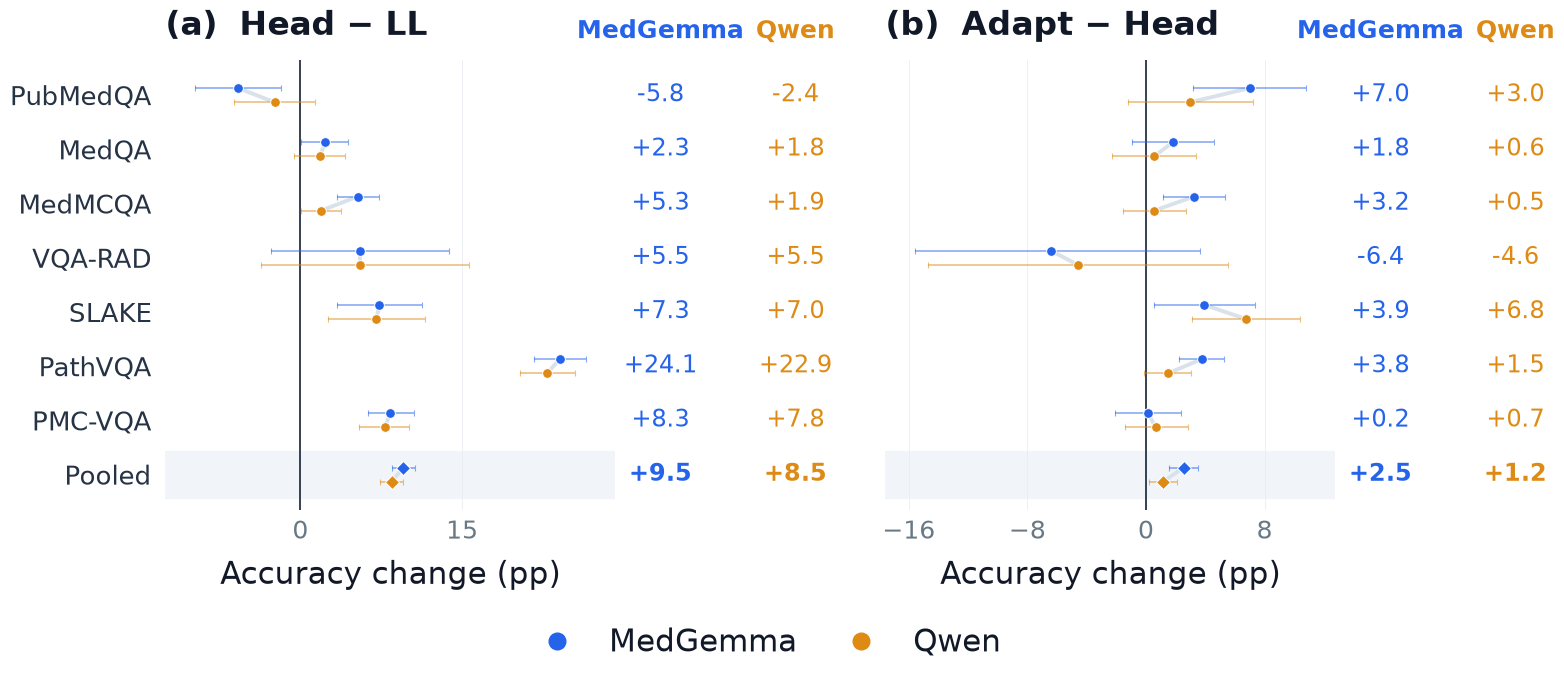

In [30]:
# Paired confidence intervals for both backbones.
comparison_order = ["LL vs Head", "Head vs Adapt"]
backbone_colors = BACKBONE_COLORS
qwen_paths = {
    "LL": ROOT / "results/qwen_ll/Qwen_Qwen2.5-VL-3B-Instruct/results.csv",
    "Head": ROOT / "results/qwen_direct_headonly/results.csv",
    "Adapt": ROOT / "results/qwen_direct_lora/results.csv",
}
qwen = {}
for method, path in qwen_paths.items():
    frame = pd.read_csv(path)
    mode = "native_generate" if method == "LL" else "qwen_direct_" + ("headonly" if method == "Head" else "lora")
    frame = frame[frame["mode"] == mode].set_index("task")
    assert frame.index.is_unique and set(frame.index) == set(DATASET_ORDER), path
    qwen[method] = frame.loc[DATASET_ORDER]
qwen_effects = {}
rng=np.random.default_rng(42)
for comparison,(reference,candidate) in zip(comparison_order, [('LL','Head'),('Head','Adapt')]):
    wide=METRICS[METRICS.method.isin(['Qwen-'+reference,'Qwen-'+candidate])].pivot(index=['dataset','id'],columns='method',values='correct')
    if wide.isna().any().any():raise ValueError('Unmatched Qwen examples')
    delta=wide['Qwen-'+candidate].astype(int)-wide['Qwen-'+reference].astype(int)
    records=[]
    for dataset in DATASET_ORDER+['__pooled__']:
        values=delta.to_numpy() if dataset=='__pooled__' else delta.loc[dataset].to_numpy()
        lo,hi=bootstrap_ci(values,rng,5000)
        records.append(dict(dataset=dataset,n=len(values),accuracy_delta=values.mean(),accuracy_ci_low=lo,accuracy_ci_high=hi))
    qwen_effects[comparison]=pd.DataFrame(records)
# Shared dumbbell design: square panels, connected backbone estimates, subtle CIs.
def draw_paired_effects(data, row_order, value, lower, upper, xlabel, stem):
    from matplotlib.ticker import MaxNLocator
    colors={'MedGemma':'#2563EB','Qwen':'#DE8B16'}
    # Square data panels; separate, aligned value columns replace floating labels.
    fig,axes=panel_grid(1,2,legend=True,sharey=True,xgap=2.7,right=2.5,top=.85)
    labels=[]
    for panel,(ax,comparison) in enumerate(zip(axes,comparison_order)):
        ax.grid(False)
        ax.grid(axis='x',color='#E7ECF2',linewidth=.7,zorder=0)
        ax.axvline(0,color='#263345',linewidth=1.3,zorder=1)
        ax.axhspan(-.43,.43,color='#F1F5FA',zorder=0)
        for spine in ax.spines.values():spine.set_visible(False)
        frames={family:data[(data.comparison==comparison)&(data.backbone==family)].set_index('dataset').loc[row_order]
                for family in colors}
        extents=[0.]
        positions={'MedGemma':1.10,'Qwen':1.40}
        for family in colors:
            labels.append(ax.text(positions[family],1.035,family,transform=ax.transAxes,
                                  ha='center',va='bottom',fontsize=18,fontweight='semibold',color=colors[family],clip_on=False))
        for i,dataset in enumerate(row_order):
            estimates=[frames[family].loc[dataset,value] for family in colors]
            ax.plot(estimates,[i+.13,i-.13],color='#D9E1EB',linewidth=2.8,solid_capstyle='round',zorder=2)
            for family,offset in [('MedGemma',.13),('Qwen',-.13)]:
                record=frames[family].loc[dataset];estimate=float(record[value]);color=colors[family]
                low,high=record[lower],record[upper]
                extents.append(estimate)
                if pd.notna(low) and pd.notna(high):
                    ax.hlines(i+offset,low,high,color=color,alpha=.48,linewidth=1.35,zorder=2)
                    ax.plot([low,high],[i+offset]*2,color=color,alpha=.55,marker='|',
                            markersize=4,linestyle='none',markeredgewidth=.8,zorder=2)
                    extents.extend([float(low),float(high)])
                ax.plot(estimate,i+offset,marker='D' if dataset.startswith('__') else 'o',linestyle='none',
                        color=color,markersize=7,markeredgecolor='white',markeredgewidth=.7,zorder=4)
                labels.append(ax.text(positions[family],i,f'{estimate:+.1f}',transform=ax.get_yaxis_transform(),
                                      ha='center',va='center',fontsize=17,
                                      fontweight='semibold' if dataset.startswith('__') else 'normal',
                                      color=color,clip_on=False))
        lo,hi=min(extents),max(extents);padding=max((hi-lo)*.075,.8)
        ax.set_xlim(lo-padding,hi+padding)
        ax.set_ylim(-.65,len(row_order)-.35)
        ax.set_yticks(np.arange(len(row_order)),[DATASET_NAMES.get(d,'Pooled' if d=='__pooled__' else 'Dataset avg.') for d in row_order])
        ax.tick_params(axis='y',pad=10,colors='#263345',labelsize=19)
        ax.tick_params(axis='x',labelsize=18,pad=7)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.set_xlabel(xlabel,fontsize=22,labelpad=11)
        title='Head − LL' if panel==0 else 'Adapt − Head'
        ax.set_title(f'({chr(97+panel)})  {title}',loc='left',fontsize=24,fontweight='semibold',pad=18)
    handles=[Line2D([],[],marker='o',color=c,linestyle='none',markersize=12) for c in colors.values()]
    legend=figure_legend(fig,handles,list(colors),ncols=2)
    for text in legend.get_texts():text.set_fontsize(22)
    save(fig,stem)
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer()
    boxes=[label.get_window_extent(renderer) for label in labels]
    for i,box in enumerate(boxes):
        if any(box.overlaps(other) for other in boxes[i+1:]):
            raise ValueError(f'{stem}: numeric-column labels overlap')
        if box.x0<0 or box.x1>fig.bbox.width or box.y0<0 or box.y1>fig.bbox.height:
            raise ValueError(f'{stem}: label outside canvas')
    plt.show()

row_order = (DATASET_ORDER + ["__pooled__"])[::-1]
export_rows=[]
for comparison in comparison_order:
    for family in ['MedGemma','Qwen']:
        frame=(paired[comparison] if family=='MedGemma' else qwen_effects[comparison]).copy()
        export_rows.append(frame.assign(backbone=family,comparison=comparison,estimate_type='paired'))
paired_accuracy_data=pd.concat(export_rows,ignore_index=True)
paired_accuracy_data.to_csv(PAPER_FIGURES/'paired_accuracy_effects_data.csv',index=False)
plot_data=paired_accuracy_data.copy()
for column in ['accuracy_delta','accuracy_ci_low','accuracy_ci_high']:
    plot_data[column]*=100

draw_paired_effects(plot_data,row_order,'accuracy_delta','accuracy_ci_low','accuracy_ci_high',
                    'Accuracy change (pp)','paired_accuracy_effects')


## Paired latency effects
Candidate minus reference p50 latency, in milliseconds; negative means faster. MedGemma uses matched per-example timing records and 2,000 paired bootstrap replicates for 95% intervals. Qwen uses saved aggregate p50 differences without intervals. The final row equally averages the seven dataset effects; it is not a pooled median.

Gray connectors join vertically separated backbone estimates; light whiskers retain available 95% intervals. Signed estimates appear in aligned columns beside each square panel. The shaded final row identifies the aggregate.


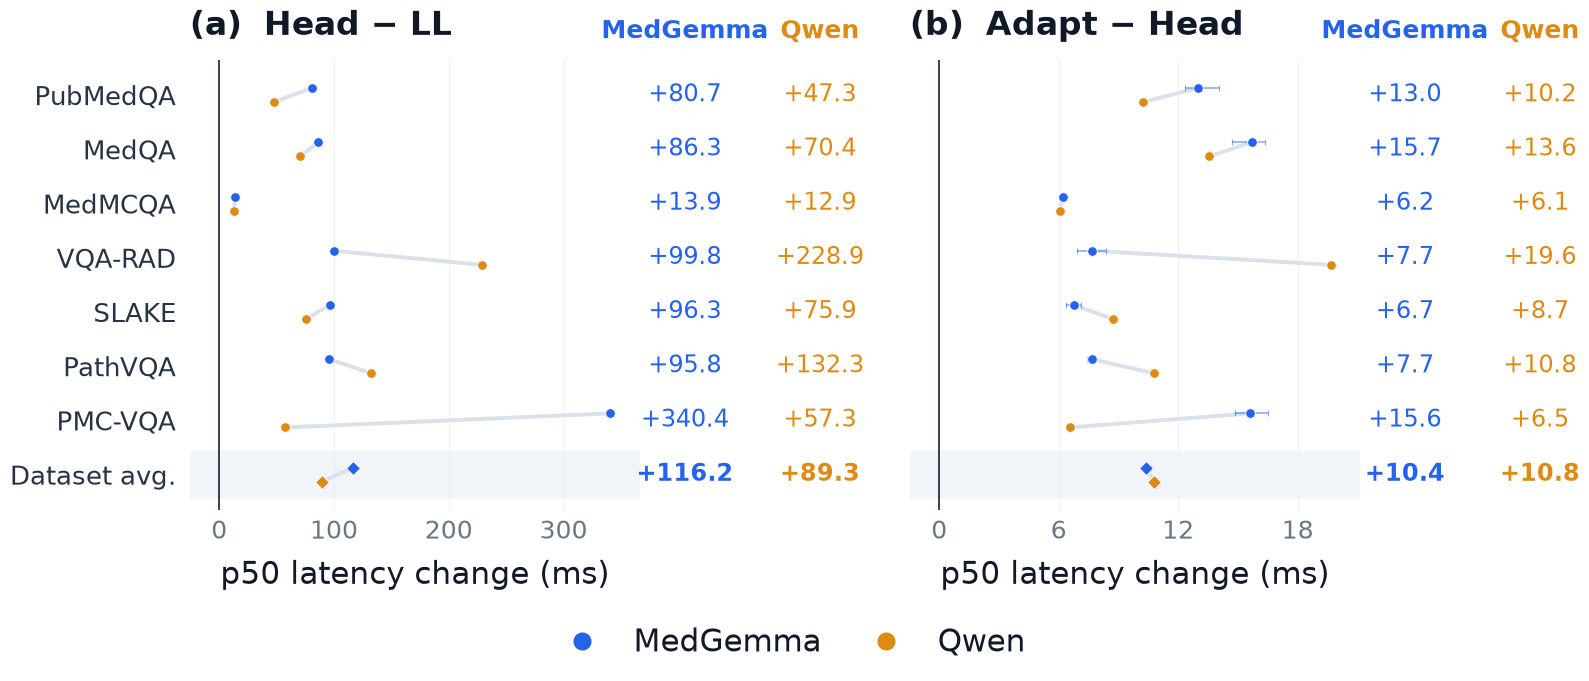

In [31]:
# Paired p50 differences for MedGemma; aggregate p50 differences for Qwen.
# Bootstrap matched example pairs, recalculating both medians each replicate.
from run_experiments import require_same
med_latency_rows = {
    "LL": [r for r in read_jsonl(ROOT / "results/medgemma_ll/details/predictions.jsonl")
           if r["mode"] == "native_generate"],
    "Head": read_jsonl(RESULTS / "medgemma-head/test.predictions.jsonl"),
    "Adapt": read_jsonl(RESULTS / "medgemma-lora/test.predictions.jsonl"),
}
rng = np.random.default_rng(42)
replicates = 2000
latency_effects = []
for comparison, (reference, candidate) in zip(comparison_order, [("LL", "Head"), ("Head", "Adapt")]):
    pairs = require_same(med_latency_rows[reference], med_latency_rows[candidate], reference, candidate)
    draws_by_dataset = []
    med_deltas = []
    for dataset in DATASET_ORDER:
        group = [(a, b) for a, b in pairs if a.get("dataset", a.get("task")) == dataset]
        values = np.asarray([[a["latency_seconds"], b["latency_seconds"]] for a, b in group]) * 1000
        if not len(values) or not np.isfinite(values).all() or (values < 0).any():
            raise ValueError(f"Invalid latency observations: {comparison}, {dataset}")
        delta = np.median(values[:, 1]) - np.median(values[:, 0])
        draws = np.empty(replicates)
        for start in range(0, replicates, 100):
            ix = rng.integers(0, len(values), (min(100, replicates - start), len(values)))
            sample = values[ix]
            draws[start:start + len(ix)] = np.median(sample[:, :, 1], axis=1) - np.median(sample[:, :, 0], axis=1)
        lo, hi = np.quantile(draws, [.025, .975])
        latency_effects.append(dict(backbone="MedGemma", comparison=comparison, dataset=dataset,
                                   latency_delta_ms=delta, ci_low=lo, ci_high=hi, n=len(values),
                                   estimate_type="paired_difference_of_medians"))
        med_deltas.append(delta)
        draws_by_dataset.append(draws)
    lo, hi = np.quantile(np.mean(draws_by_dataset, axis=0), [.025, .975])
    latency_effects.append(dict(backbone="MedGemma", comparison=comparison, dataset="__average__",
                               latency_delta_ms=np.mean(med_deltas), ci_low=lo, ci_high=hi,
                               n=len(pairs), estimate_type="dataset_average_paired_difference"))
    ref, cand = qwen[reference], qwen[candidate]
    assert np.array_equal(ref.n, cand.n)
    deltas = cand.p50_latency - ref.p50_latency
    for dataset in DATASET_ORDER + ["__average__"]:
        latency_effects.append(dict(backbone="Qwen", comparison=comparison, dataset=dataset,
                                   latency_delta_ms=deltas.mean() if dataset == "__average__" else deltas.loc[dataset],
                                   ci_low=np.nan, ci_high=np.nan,
                                   n=ref.n.sum() if dataset == "__average__" else ref.n.loc[dataset],
                                   estimate_type="aggregate_difference_of_medians"))
latency_effects = pd.DataFrame(latency_effects)
latency_effects.to_csv(PAPER_FIGURES / "paired_latency_effects_data.csv", index=False)
latency_row_order = (DATASET_ORDER + ["__average__"])[::-1]
draw_paired_effects(latency_effects,latency_row_order,'latency_delta_ms','ci_low','ci_high',
                    'p50 latency change (ms)','paired_latency_effects')


## Visual dependence
Paired changes from the correct-image condition for MedGemma NAR and Adapt. No matching Qwen image-ablation export is available. Error bars are the saved paired 95% intervals.

The NAR ablation is the legacy `laya-med` checkpoint from `a.ipynb`; no equivalent vision-LoRA NAR image-ablation export is available.


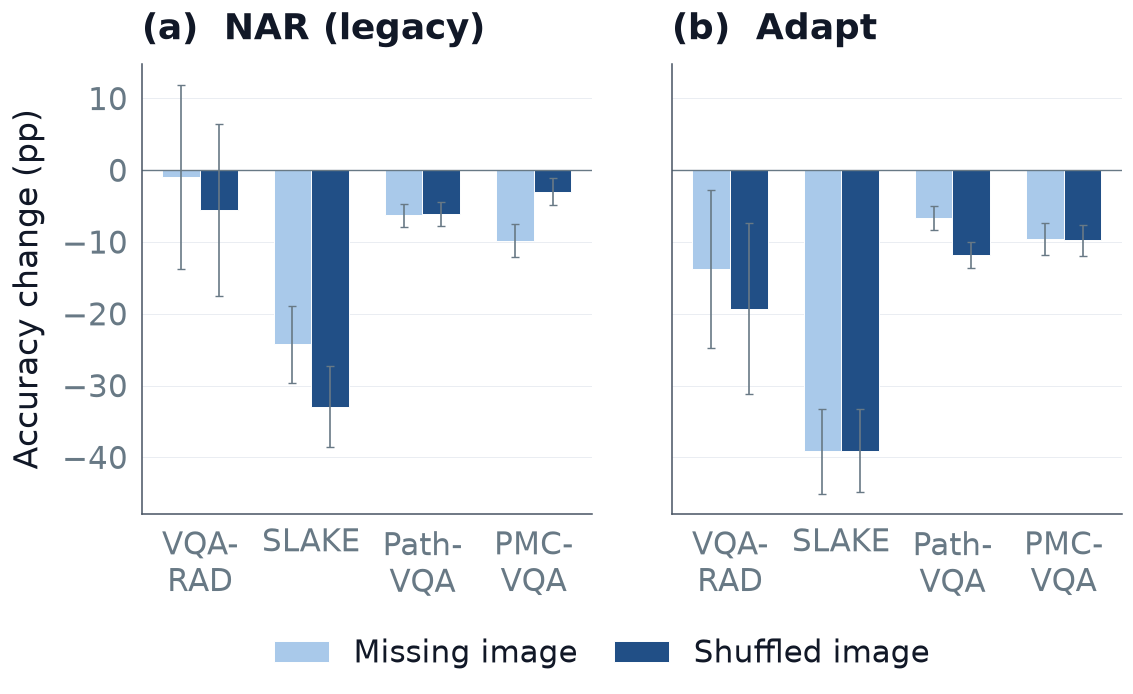

In [8]:
# Paired image-dependence ablation: accuracy change from the correct image.
IMAGE_DATASETS = ["vqarad", "slake", "path_vqa", "pmc_vqa"]
visual_frames = {
    "NAR (legacy)": visual_laya[visual_laya.dataset.isin(IMAGE_DATASETS)].copy(),
    "Adapt": visual_lora[visual_lora.dataset.isin(IMAGE_DATASETS)].copy(),
}
conditions = ["missing_image", "shuffled_image"]
condition_colors = {"missing_image": "#A9C9EA", "shuffled_image": "#214F86"}
fig, axes = panel_grid(1, 2, legend=True, sharey=True)
x = np.arange(len(IMAGE_DATASETS))
width = .34
for ax, (model, frame) in zip(axes, visual_frames.items()):
    for offset, condition in enumerate(conditions):
        subset = frame[frame.condition == condition].set_index("dataset").reindex(IMAGE_DATASETS)
        delta = subset.delta.to_numpy() * 100
        lower = (subset.delta - subset.ci_low).to_numpy() * 100
        upper = (subset.ci_high - subset.delta).to_numpy() * 100
        ax.bar(x + (offset - .5) * width, delta, width, color=condition_colors[condition],
               label=condition.replace("_", " ").capitalize(), edgecolor="white", linewidth=.7,
               yerr=np.vstack([lower, upper]), capsize=3, error_kw={"ecolor": MUTED, "elinewidth": 1.2})
    ax.axhline(0, color=MUTED, linewidth=1)
    panel_title(ax, list(visual_frames).index(model), model)
    ax.set_xticks(x, ["VQA-\nRAD", "SLAKE", "Path-\nVQA", "PMC-\nVQA"])
axes[0].set_ylabel("Accuracy change (pp)")
handles, labels = axes[0].get_legend_handles_labels()
figure_legend(fig, handles, labels, ncols=2)
save(fig, "visual_dependence_ablation")
plt.show()


## Post-hoc risk–coverage
NAR and verified Qwen Head/Adapt test cohorts. Lines are confidence-threshold routing; diamonds show saved conformal singleton decisions. The overall panel equally weights datasets.


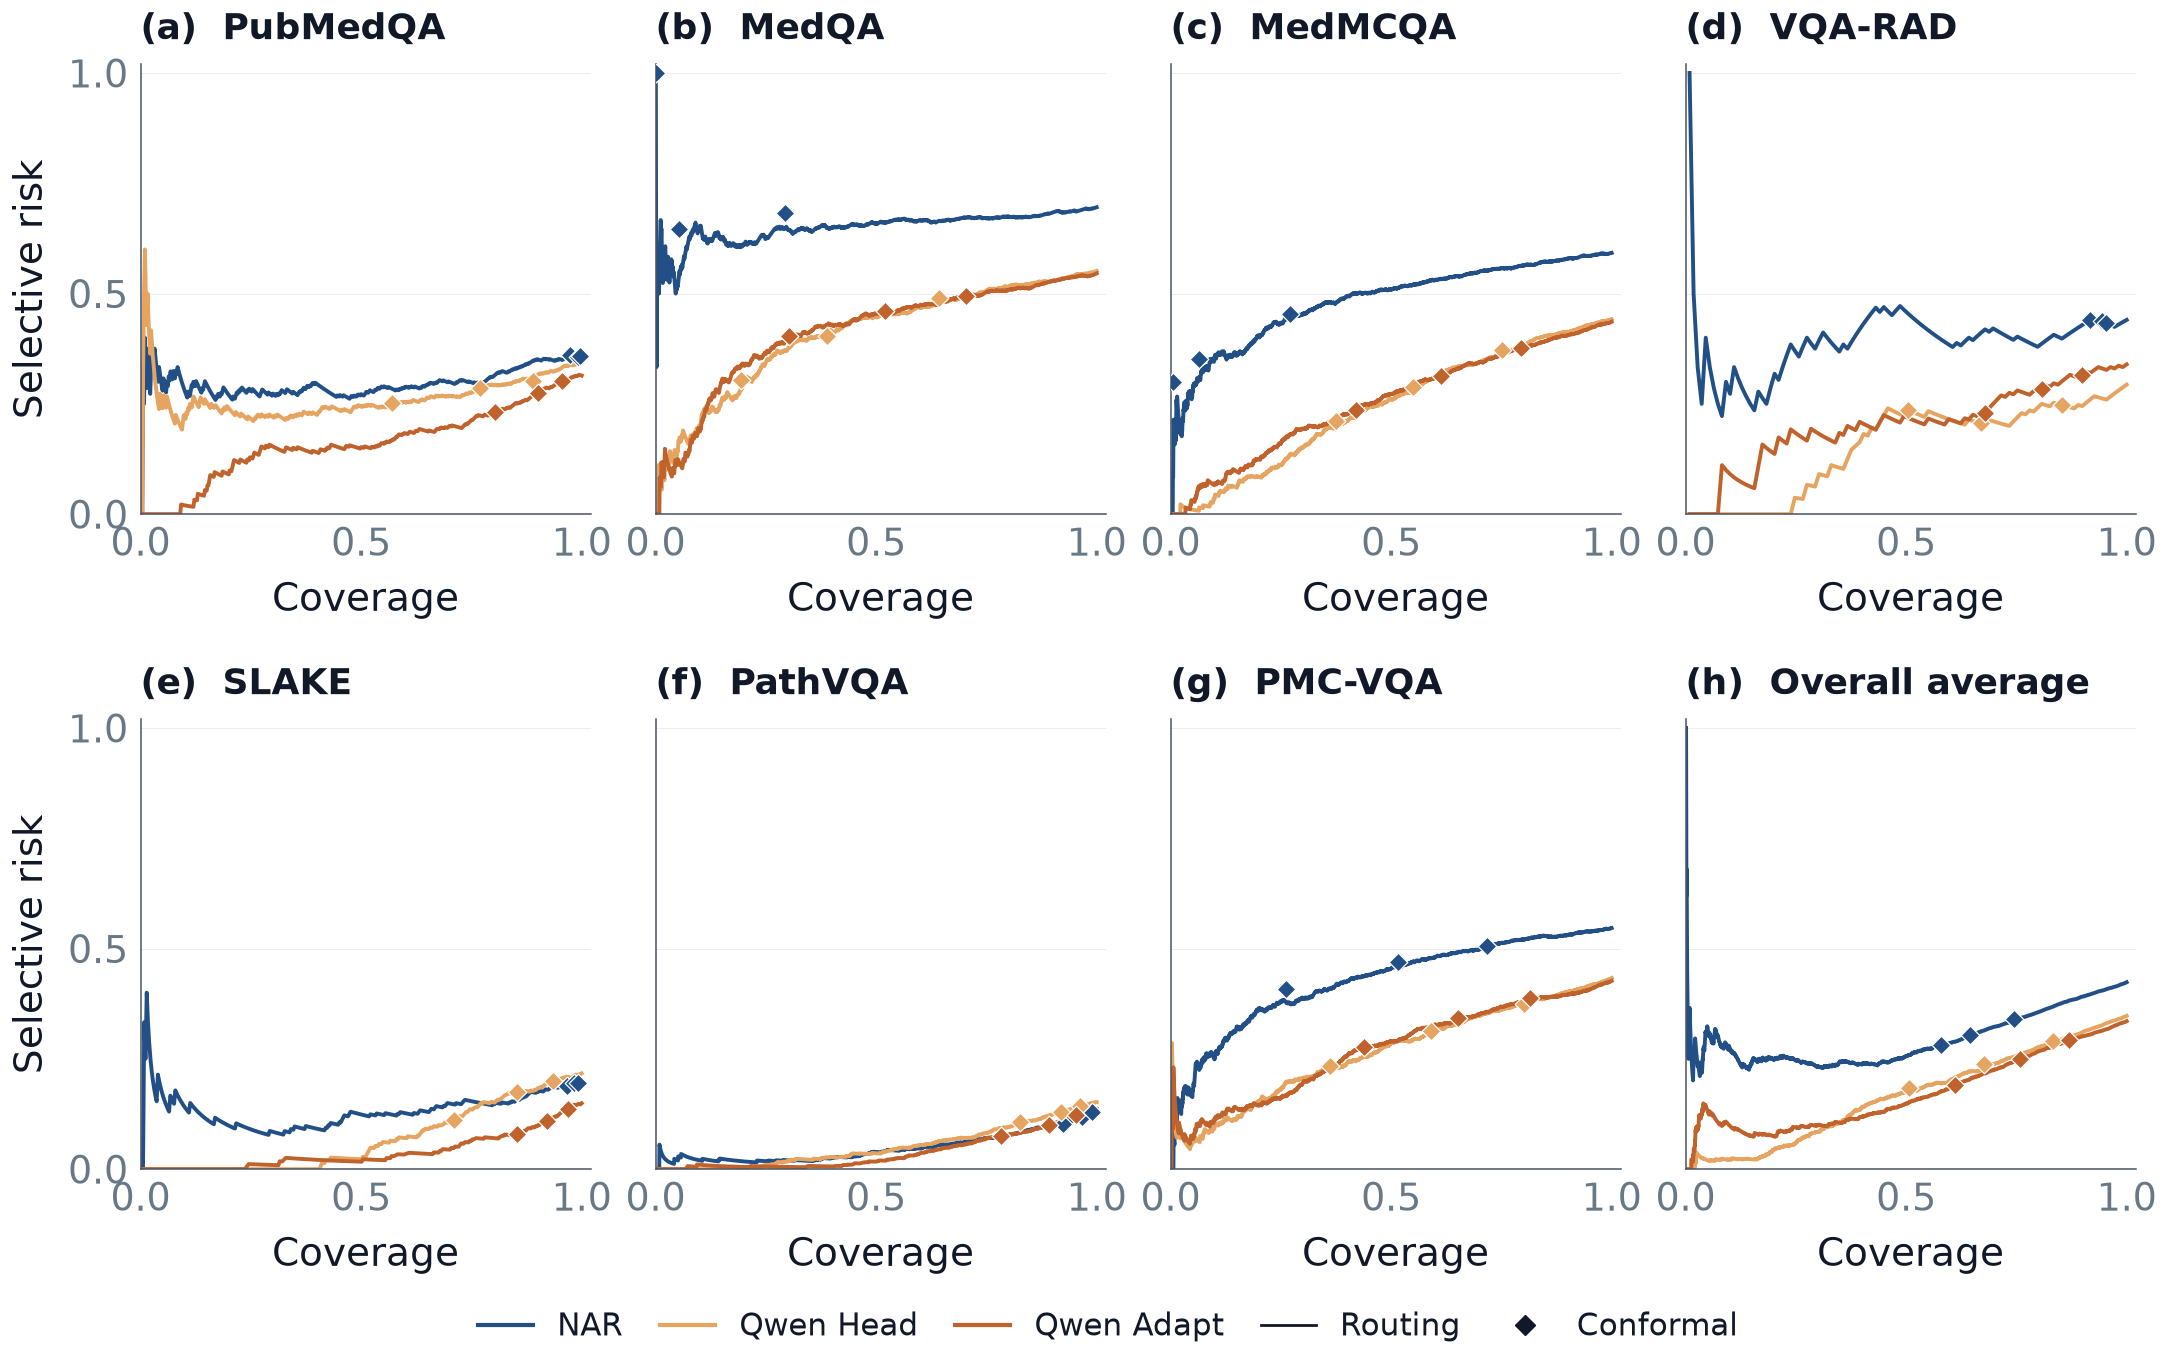

In [9]:
# Reuse saved NAR policies and verified Qwen conformal sets at their evaluated alphas.
POLICY_MODELS = ['NAR','Qwen-Head','Qwen-Adapt']
POLICY_COLORS = {'NAR':'#214F86','Qwen-Head':'#E6A461','Qwen-Adapt':'#BF622B'}
policy_points = []
for method, saved in SAVED_CONFORMAL.items():
    for result in saved['results']:
        frame = pd.DataFrame(result['rows'])
        for dataset, group in frame.groupby('dataset'):
            singleton = group[group.set_size == 1]
            policy_points.append(dict(method=method,dataset=dataset,alpha=result['alpha'],n=len(group),
                                     coverage=len(singleton)/len(group), risk=1-singleton.covered.mean(),
                                     empirical_coverage=group.covered.mean(), mean_set_size=group.set_size.mean()))
policy_points = pd.DataFrame(policy_points)
rng = np.random.default_rng(42)
coverage_records = []
for (method, alpha), frame in policy_points.groupby(['method','alpha']):
    assert set(frame.dataset) == set(DATASET_ORDER)
    sizes = frame.n.to_numpy(dtype=int)
    rates = frame.empirical_coverage.to_numpy()
    draws = rng.binomial(sizes, rates, size=(5000,len(frame))) / sizes
    for j, row in enumerate(frame.itertuples()):
        lo,hi=np.quantile(draws[:,j],[.025,.975])
        coverage_records.append(dict(method=method,dataset=row.dataset,alpha=alpha,target=1-alpha,
                                     observed=row.empirical_coverage,low=lo,high=hi,set_size=row.mean_set_size))
    lo,hi=np.quantile(draws.mean(axis=1),[.025,.975])
    coverage_records.append(dict(method=method,dataset='__overall__',alpha=alpha,target=1-alpha,
                                 observed=rates.mean(),low=lo,high=hi,set_size=frame.mean_set_size.mean()))
coverage_frame = pd.DataFrame(coverage_records)
coverage_frame.to_csv(PAPER_FIGURES / 'overall_conformal_coverage.csv',index=False)
policy_points.to_csv(PAPER_FIGURES / 'conformal_policy_data.csv',index=False)

# Threshold routing keeps tied confidence values together. Overall curves use equal dataset weights.
routing_records = []
for method in POLICY_MODELS:
    for dataset in DATASET_ORDER + ['__overall__']:
        frame = METRICS[METRICS.method == method].copy()
        if dataset != '__overall__':
            frame = frame[frame.dataset == dataset]
        weights = 1/frame.groupby('dataset').correct.transform('size') if dataset=='__overall__' else np.ones(len(frame))
        frame['weight'] = weights
        frame['error_weight'] = (~frame.correct) * frame.weight
        grouped = frame.groupby('confidence')[['weight','error_weight']].sum().sort_index(ascending=False).cumsum()
        for tau,row in grouped.iterrows():
            routing_records.append(dict(method=method,dataset=dataset,threshold=tau,
                                        coverage=row.weight/frame.weight.sum(),risk=row.error_weight/row.weight))
routing_frame = pd.DataFrame(routing_records)
routing_frame.to_csv(PAPER_FIGURES / 'overall_posthoc_risk_coverage.csv',index=False)
fig, axes = panel_grid(2,4,legend=True,sharex=True,sharey=True,xgap=.65,ygap=2.05)
for index,dataset in enumerate(DATASET_ORDER + ['__overall__']):
    ax=axes.flat[index]
    for method in POLICY_MODELS:
        curve=routing_frame[(routing_frame.method==method)&(routing_frame.dataset==dataset)].sort_values('coverage')
        ax.plot(curve.coverage,curve.risk,color=POLICY_COLORS[method],linewidth=2.8)
        points=policy_points[policy_points.method==method]
        if dataset=='__overall__':
            rows=[]
            for alpha,g in points.groupby('alpha'):
                coverage=g.coverage.mean()
                rows.append(dict(coverage=coverage,risk=(g.risk.fillna(0)*g.coverage).mean()/coverage if coverage else np.nan))
            points=pd.DataFrame(rows)
        else:
            points=points[points.dataset==dataset]
        ax.scatter(points.coverage,points.risk,color=POLICY_COLORS[method],marker='D',s=90,edgecolor='white',linewidth=.9,zorder=5)
    panel_title(ax,index,'Overall average' if dataset=='__overall__' else DATASET_NAMES[dataset])
    ax.set(xlim=(0,1.02),ylim=(0,1.02),xlabel='Coverage',xticks=[0,.5,1],yticks=[0,.5,1])
    if index%4==0:ax.set_ylabel('Selective risk')
handles=[Line2D([],[],color=POLICY_COLORS[m],linewidth=3) for m in POLICY_MODELS]
handles += [Line2D([],[],color=INK,linewidth=2),Line2D([],[],color=INK,marker='D',linestyle='none')]
figure_legend(fig,handles,['NAR','Qwen Head','Qwen Adapt','Routing','Conformal'],ncols=5)
enlarge_coverage_axes(axes)
save(fig,'posthoc_risk_coverage')
plt.show()


## Conformal coverage and prediction-set size
Coverage intervals use 5,000 bootstrap replicates of covered/not-covered outcomes; overall intervals are stratified by dataset. Set size is shown separately to keep the coverage panels readable. Only evaluated alpha values are plotted.


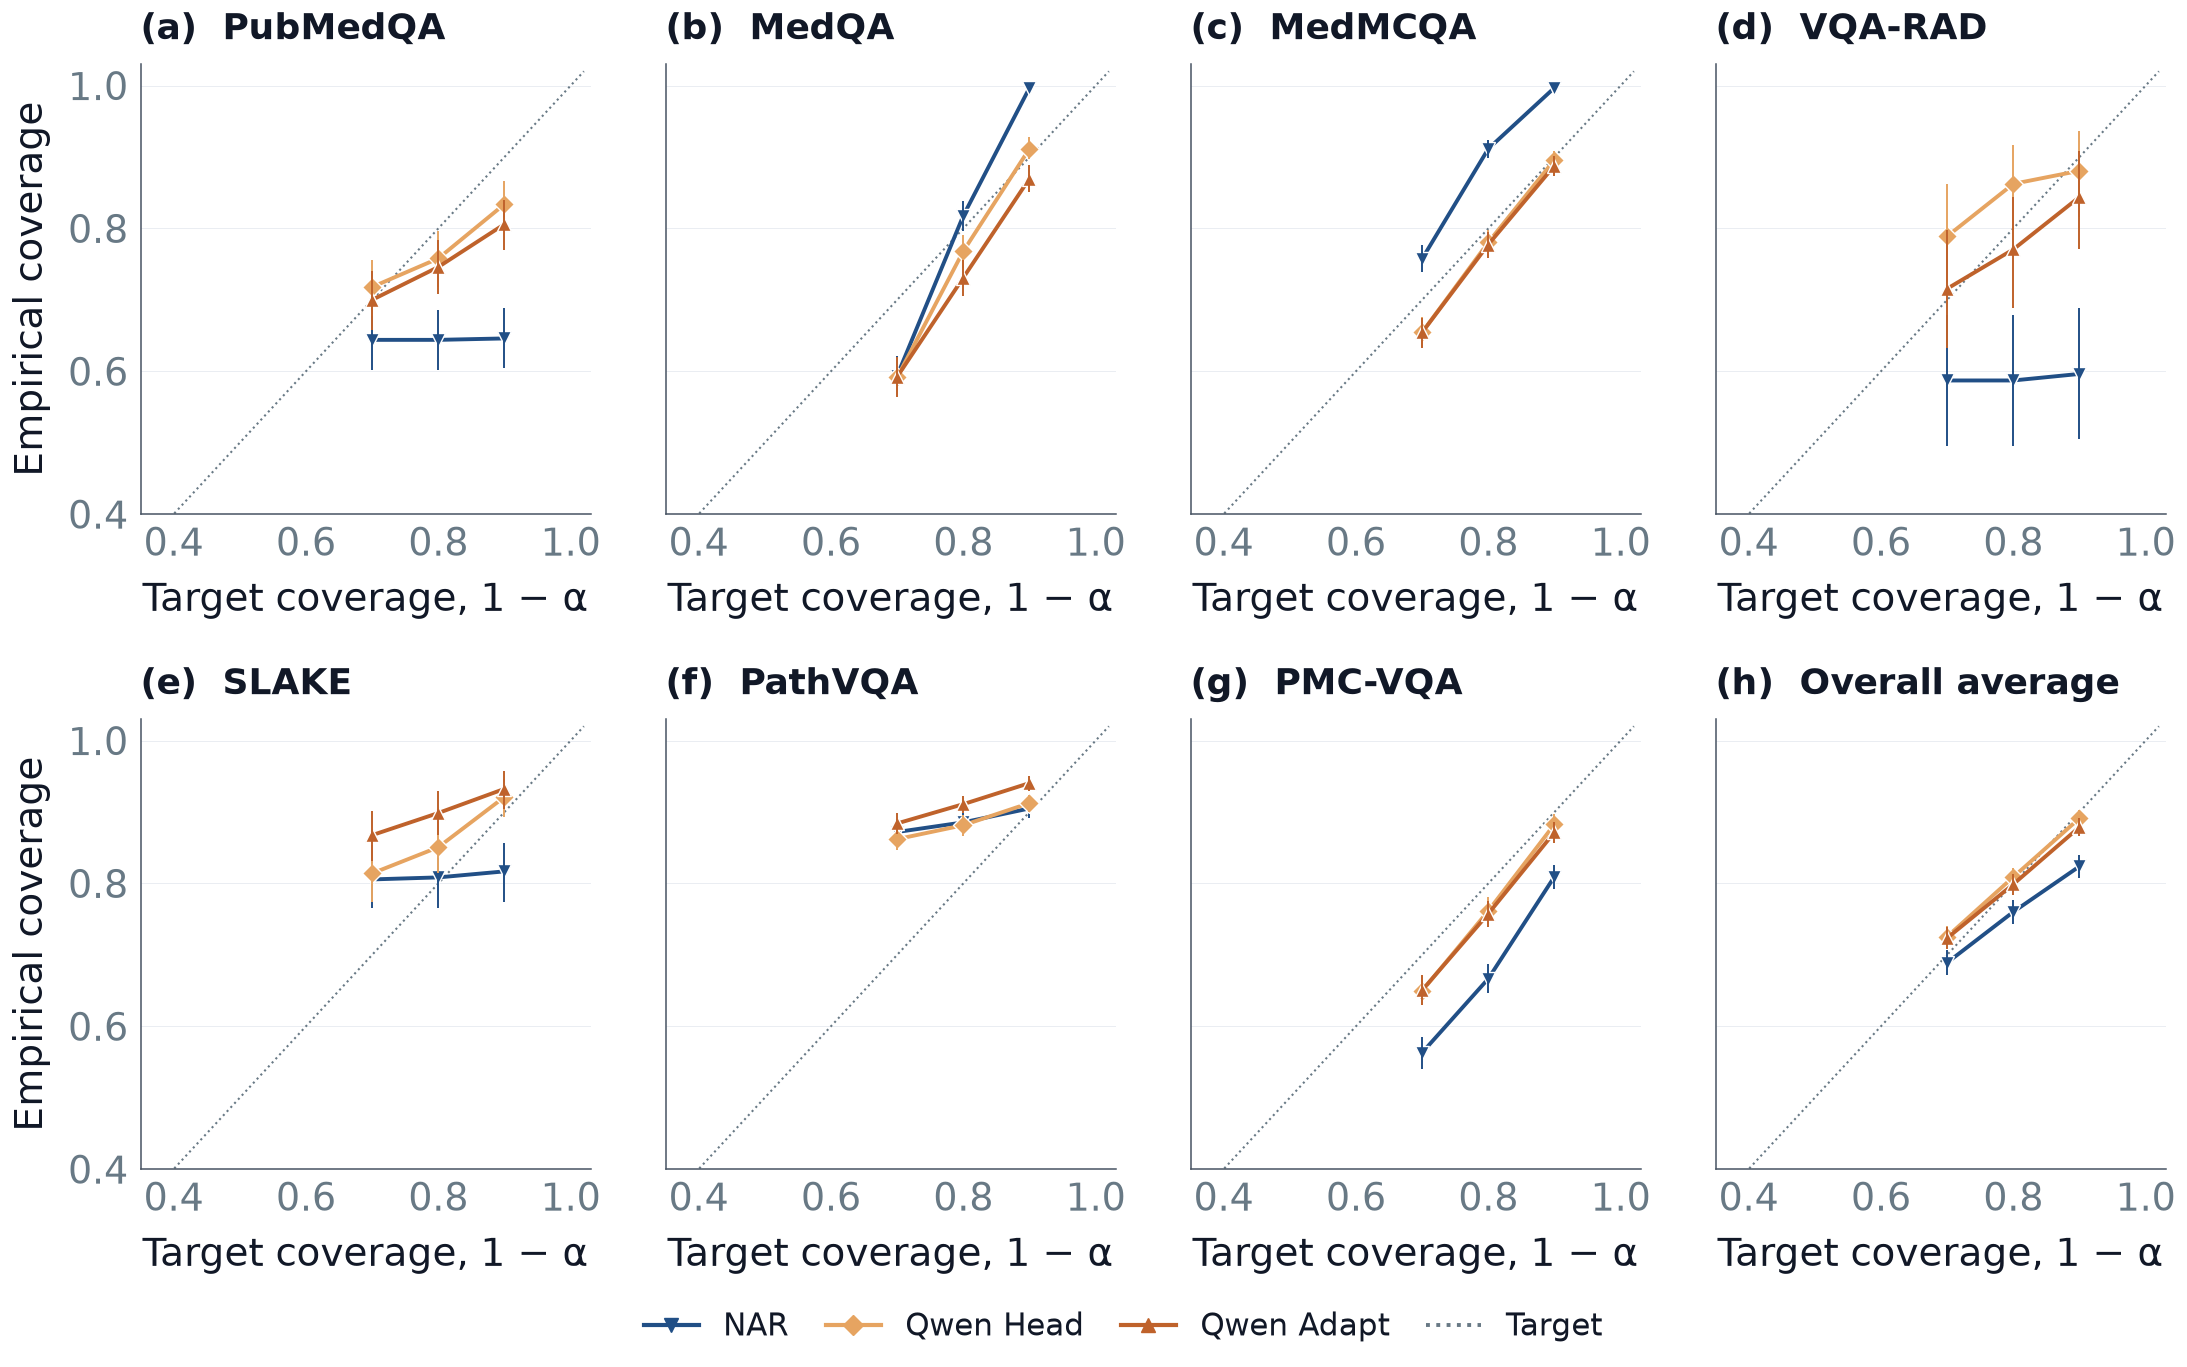

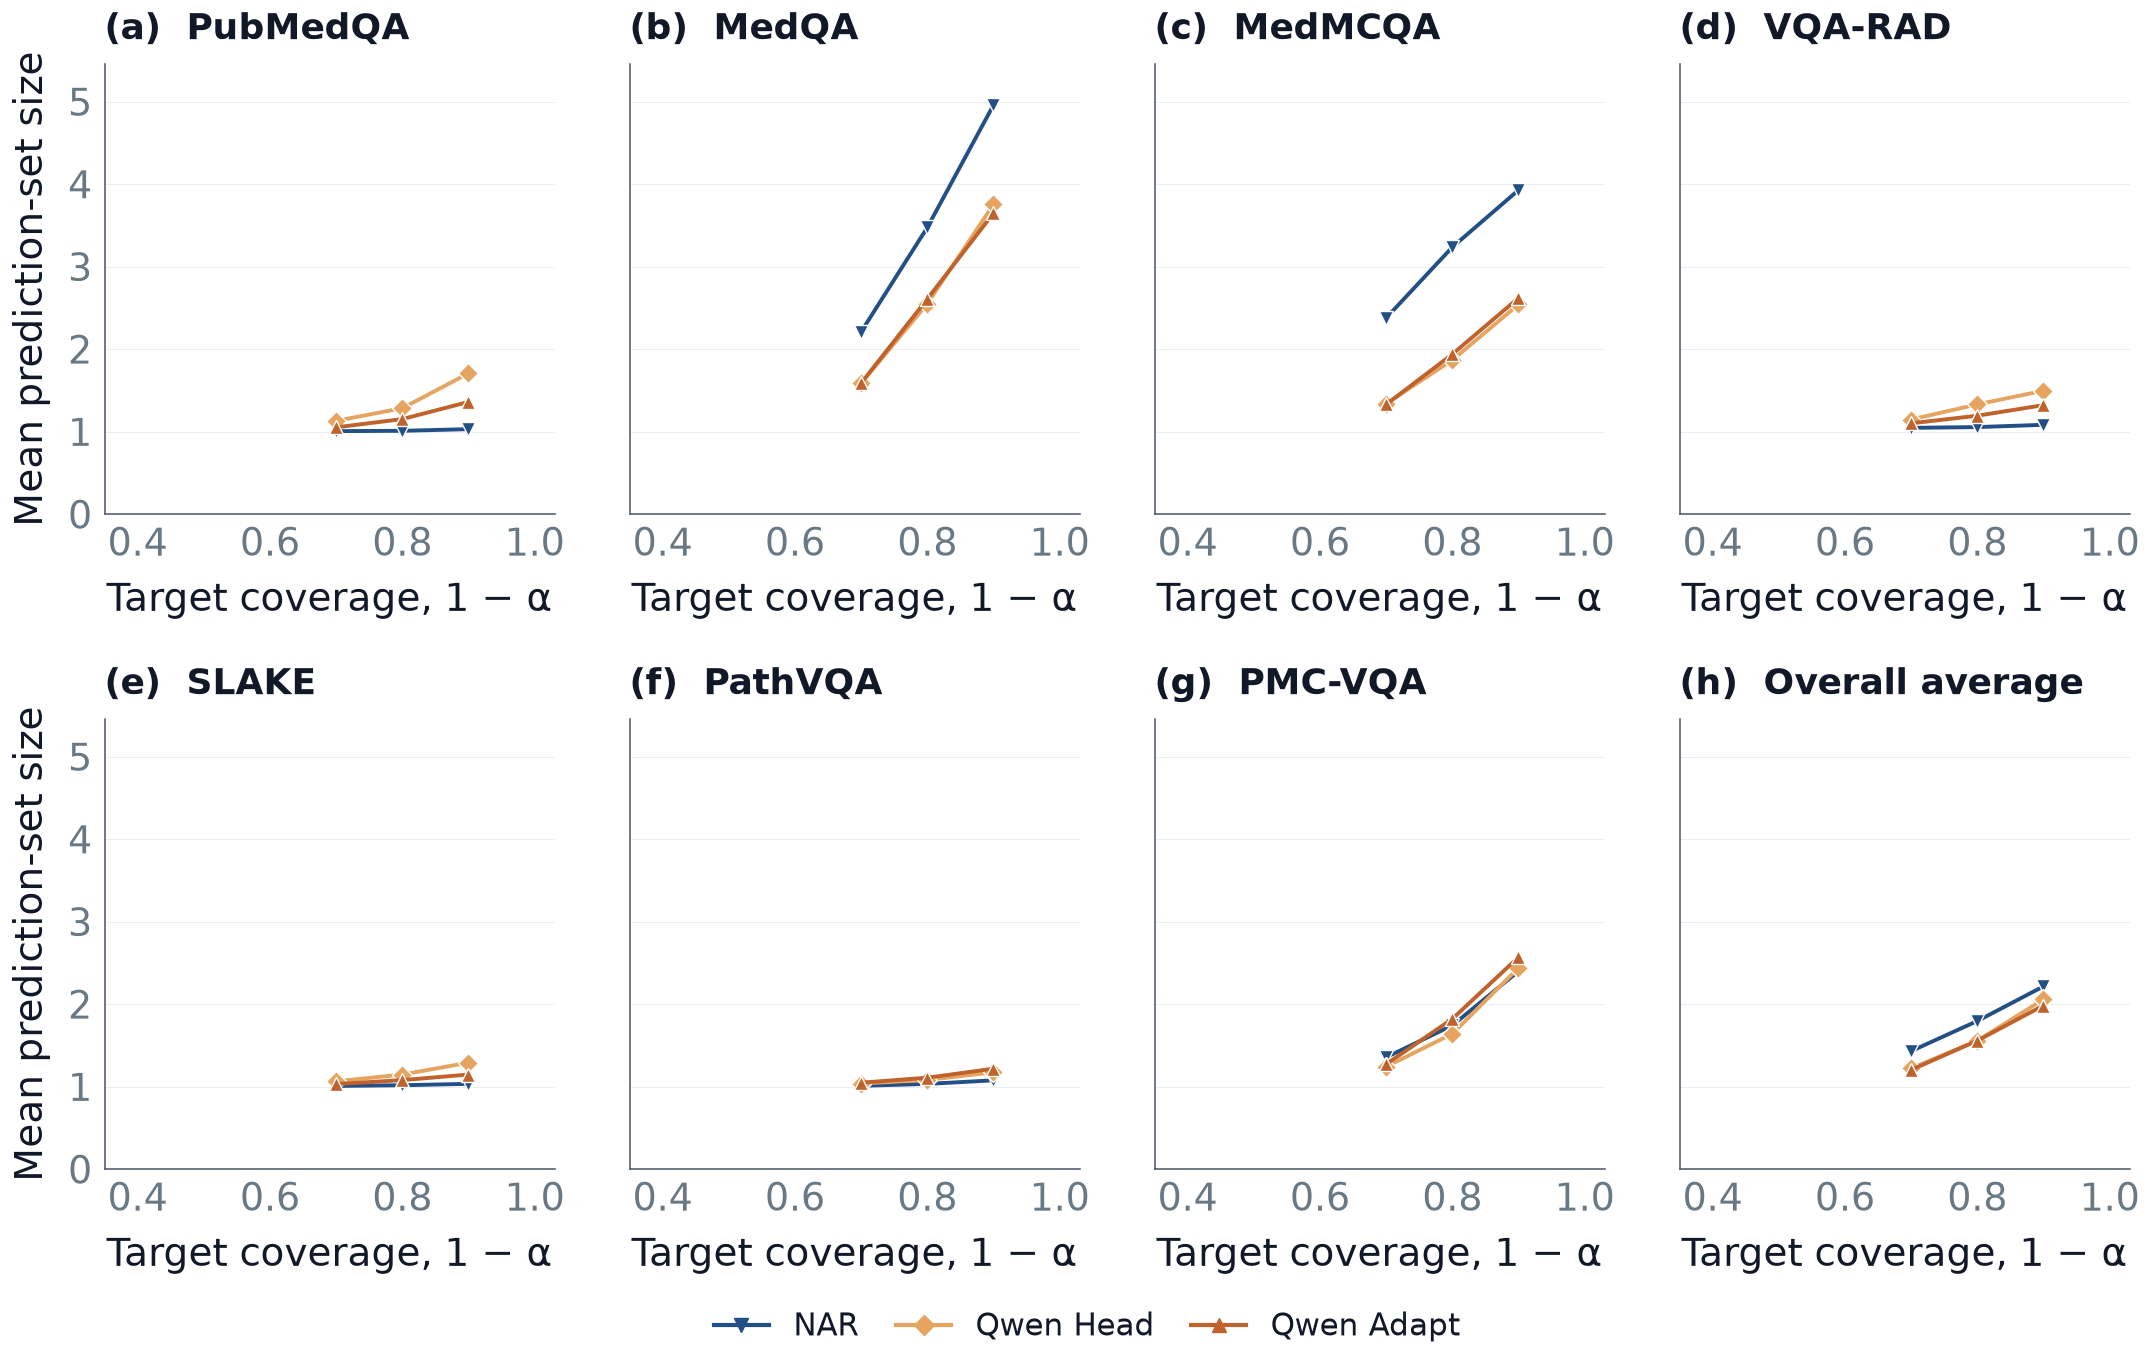

In [10]:
# Put set size in its own companion figure instead of crowding the coverage curves.
for metric, ylabel, stem in [('observed','Empirical coverage','conformal_coverage'),
                              ('set_size','Mean prediction-set size','conformal_set_size')]:
    fig,axes=panel_grid(2,4,legend=True,sharex=True,sharey=True,xgap=.75,ygap=2.05)
    lower=max(0,min(.6,coverage_frame.low.min())-.03)
    for index,dataset in enumerate(DATASET_ORDER+['__overall__']):
        ax=axes.flat[index]
        if metric=='observed':
            ax.plot([.35,1.02],[.35,1.02],color=MUTED,linestyle=':',linewidth=1.5)
        for method in POLICY_MODELS:
            frame=coverage_frame[(coverage_frame.method==method)&(coverage_frame.dataset==dataset)].sort_values('target')
            ax.plot(frame.target,frame[metric],color=POLICY_COLORS[method],marker={'NAR':'v','Qwen-Head':'D','Qwen-Adapt':'^'}[method],
                    markersize=10,linewidth=2.8,markeredgecolor='white')
            if metric=='observed':
                ax.vlines(frame.target,frame.low,frame.high,color=POLICY_COLORS[method],linewidth=1.4)
        panel_title(ax,index,'Overall average' if dataset=='__overall__' else DATASET_NAMES[dataset])
        ax.set(xlim=(.35,1.03),xticks=[.4,.6,.8,1],xlabel='Target coverage, 1 − α')
        if metric=='observed':ax.set(ylim=(lower,1.03),yticks=[.4,.6,.8,1])
        else:ax.set_ylim(0,max(3,coverage_frame.set_size.max()*1.1))
        if index%4==0:ax.set_ylabel(ylabel)
    handles=[Line2D([],[],color=POLICY_COLORS[m],marker={'NAR':'v','Qwen-Head':'D','Qwen-Adapt':'^'}[m],linewidth=3) for m in POLICY_MODELS]
    labels=['NAR','Qwen Head','Qwen Adapt']
    if metric=='observed':
        handles.append(Line2D([],[],color=MUTED,linestyle=':'));labels.append('Target')
    figure_legend(fig,handles,labels,ncols=len(labels))
    enlarge_coverage_axes(axes)
    save(fig,stem)
    plt.show()


## Candidate-count scaling
MedGemma NAR timing measurements, retaining the original dataset and component breakdowns. Qwen has no equivalent saved timing decomposition.

These are the original legacy NAR measurements from `a.ipynb`, not the vision-LoRA baseline.


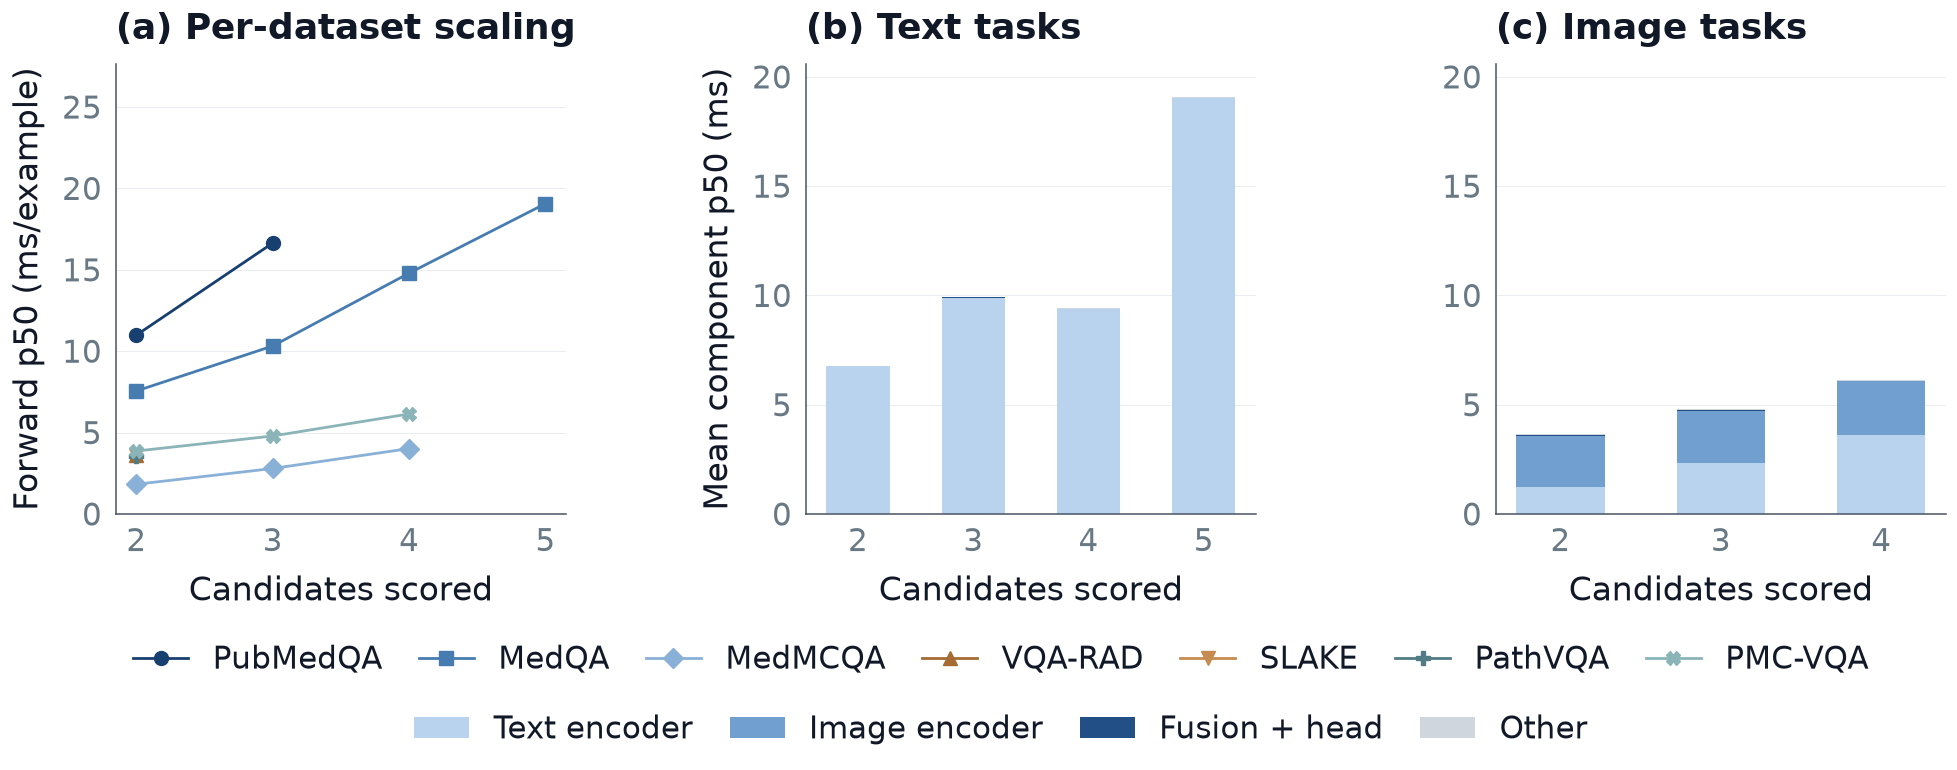

In [11]:
# Laya-Med inference cost as candidates grow, plus forward-pass composition by task type.
scaling["task_group"] = np.where(scaling.dataset.isin(IMAGE_SET), "Image tasks", "Text tasks")
fig, axes = panel_grid(1, 3, legend=True, xgap=2.4)
dataset_colors = ['#173F70','#477CB1','#89B1D8','#A66B32','#C58B50','#527C85','#8BB4B8']
dataset_markers = ['o','s','D','^','v','P','X']
for dataset_index, dataset in enumerate(DATASET_ORDER):
    frame = scaling[scaling.dataset == dataset].sort_values("candidate_count")
    if frame.empty:
        continue
    axes[0].plot(frame.candidate_count, frame.forward_p50_ms_per_example,
                 marker=dataset_markers[dataset_index], color=dataset_colors[dataset_index], markersize=10, linewidth=2, label=DATASET_NAMES[dataset])
axes[0].set_xlabel("Candidates scored")
axes[0].set_xticks([2, 3, 4, 5])
axes[0].set_ylabel("Forward p50 (ms/example)")
axes[0].set_ylim(0, scaling.forward_p50_ms_per_example.max() * 1.45)
axes[0].set_title("(a) Per-dataset scaling", loc="left", pad=18)
dataset_handles, dataset_labels = axes[0].get_legend_handles_labels()
figure_legend(fig, dataset_handles, dataset_labels, ncols=7, row=1)
component_cols = ["text_encoder_p50_ms_per_example", "image_encoder_p50_ms_per_example",
                  "fusion_head_p50_ms_per_example", "other_forward_p50_ms_per_example"]
component_labels = ["Text encoder", "Image encoder", "Fusion + head", "Other"]
component_colors = ["#B9D2EE", "#709FD0", "#214F86", "#CFD6DE"]
summary_scaling = scaling.groupby(["task_group", "candidate_count"], as_index=False)[component_cols].mean()
top = summary_scaling[component_cols].sum(axis=1).max() * 1.08
for ax, task_group, tag in [(axes[1], "Text tasks", "(b)"), (axes[2], "Image tasks", "(c)")]:
    frame = summary_scaling[summary_scaling.task_group == task_group].sort_values("candidate_count")
    bottom = np.zeros(len(frame))
    for column, label, color in zip(component_cols, component_labels, component_colors):
        values = frame[column].to_numpy()
        ax.bar(frame.candidate_count, values, width=.55, bottom=bottom, color=color,
               edgecolor="none", label=label)
        bottom += values
    ax.set_xticks(frame.candidate_count.astype(int))
    ax.set_xlabel("Candidates scored")
    ax.set_ylim(0, top)
    ax.set_title(f"{tag} {task_group}", loc="left", pad=18)
axes[1].set_ylabel("Mean component p50 (ms)")
handles, labels = axes[1].get_legend_handles_labels()
figure_legend(fig, handles, labels, ncols=4)
save(fig, "candidate_count_scaling")
plt.show()


## Paired effects table
Accuracy and latency estimates matching the figures, exported to CSV and LaTeX.


In [12]:
# Export the same matched accuracy effects shown in the figure, for both backbones.
accuracy_export=pd.read_csv(PAPER_FIGURES/'paired_accuracy_effects_data.csv')
latency_export=pd.read_csv(PAPER_FIGURES/'paired_latency_effects_data.csv')
records=[]
for row in accuracy_export[accuracy_export.dataset!='__pooled__'].itertuples():
    lat=latency_export[(latency_export.backbone==row.backbone)&(latency_export.comparison==row.comparison)&(latency_export.dataset==row.dataset)].iloc[0]
    interval=f'{100*row.accuracy_delta:+.1f} [{100*row.accuracy_ci_low:+.1f}, {100*row.accuracy_ci_high:+.1f}]'
    latency=f'{lat.latency_delta_ms:+.1f}'
    if pd.notna(lat.ci_low):latency+=f' [{lat.ci_low:+.1f}, {lat.ci_high:+.1f}]'
    records.append({'Backbone':row.backbone,'Comparison':row.comparison,'Dataset':DATASET_NAMES[row.dataset],
                    'n':row.n,'Accuracy change (pp), 95% CI':interval,'p50 change (ms), 95% CI':latency})
paired_export=pd.DataFrame(records)
paired_export.to_csv(PAPER_FIGURES/'paired_effects_table.csv',index=False)
(PAPER_FIGURES/'paired_effects_table.tex').write_text(paired_export.to_latex(index=False,escape=True,longtable=True,
    caption='Candidate minus reference effects. Accuracy intervals use matched examples for both backbones. Qwen latency differences use aggregate p50 values and have no intervals.',label='tab:paired_effects'))
display(paired_export)


,Backbone,Comparison,Dataset,n,"Accuracy change (pp), 95% CI","p50 change (ms), 95% CI"
0,MedGemma,LL vs Head,PMC-VQA,1980,"+8.3 [+6.3, +10.6]","+340.4 [+339.7, +340.9]"
1,MedGemma,LL vs Head,PathVQA,2000,"+24.1 [+21.6, +26.5]","+95.8 [+95.2, +96.4]"
2,MedGemma,LL vs Head,SLAKE,355,"+7.3 [+3.4, +11.3]","+96.3 [+95.9, +96.7]"
3,MedGemma,LL vs Head,VQA-RAD,109,"+5.5 [-2.8, +13.8]","+99.8 [+98.9, +100.6]"
4,MedGemma,LL vs Head,MedMCQA,2000,"+5.3 [+3.3, +7.2]","+13.9 [+13.8, +14.1]"
5,MedGemma,LL vs Head,MedQA,1268,"+2.3 [+0.1, +4.4]","+86.3 [+84.8, +88.2]"
6,MedGemma,LL vs Head,PubMedQA,500,"-5.8 [-9.8, -1.8]","+80.7 [+78.6, +81.6]"
7,Qwen,LL vs Head,PMC-VQA,1980,"+7.8 [+5.5, +10.1]",+57.3
8,Qwen,LL vs Head,PathVQA,2000,"+22.9 [+20.3, +25.4]",+132.3
9,Qwen,LL vs Head,SLAKE,355,"+7.0 [+2.5, +11.5]",+75.9


## Error overlap
Within-backbone comparisons on the same matched test examples. A single row of MedGemma and Qwen panels preserves readable cells; all panels share a common percentage scale.


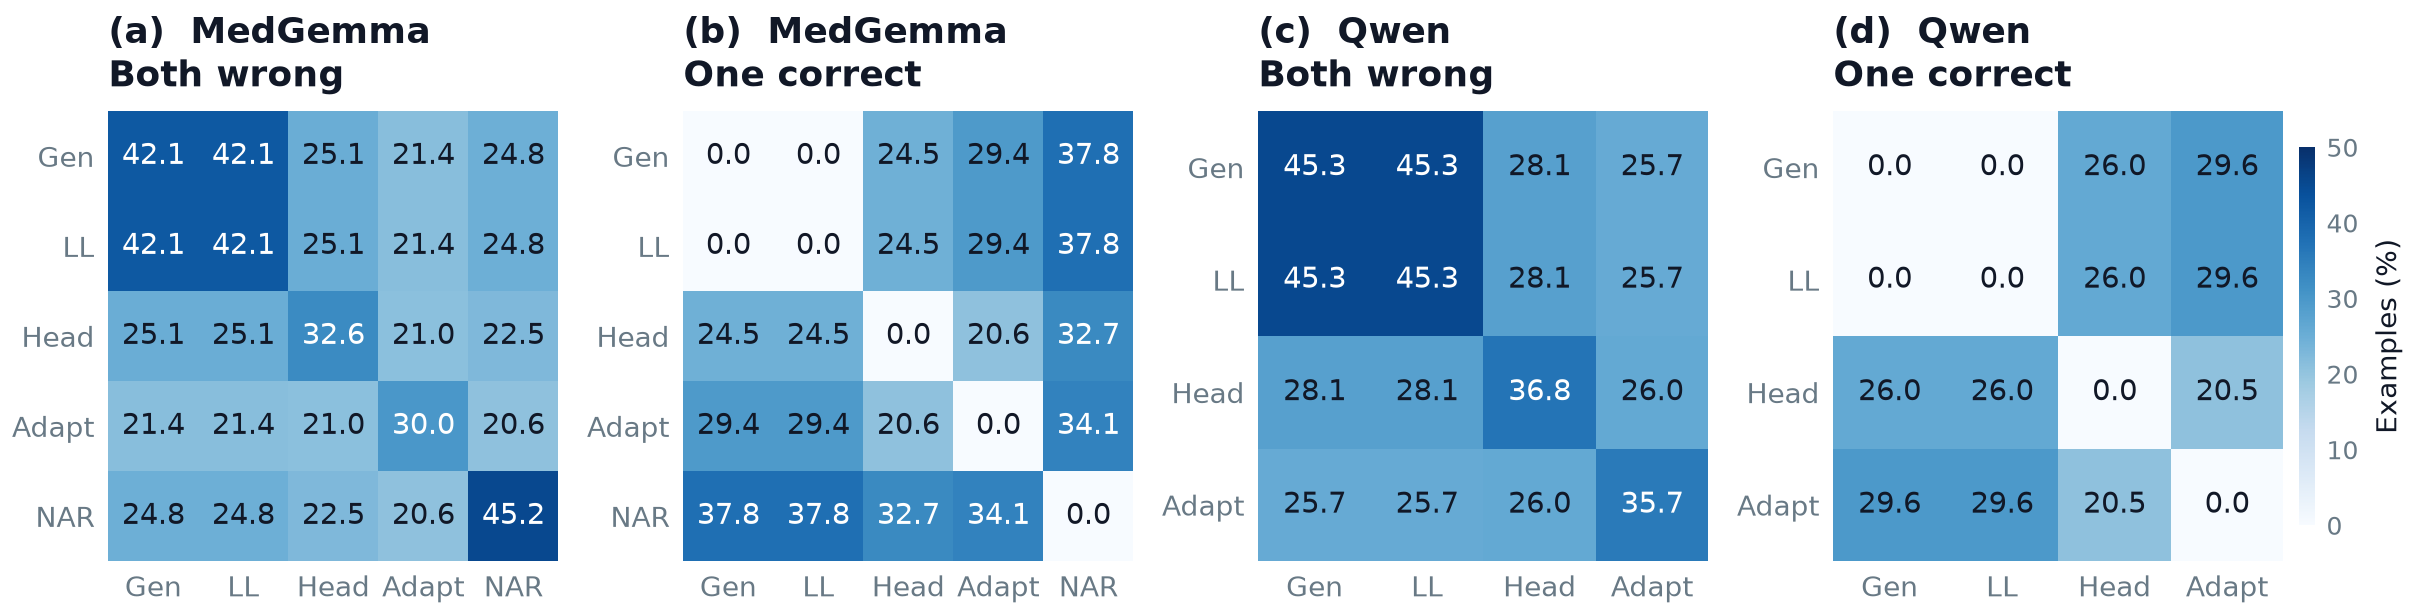

In [13]:
# Separate backbone panels keep labels legible at the original 4.5-inch panel size.
fig,axes=panel_grid(1,4,sharex=False,sharey=False,xgap=1.25,top=1.45)
error_rows=[]
matrices=[]
for family in ['MedGemma','Qwen']:
    methods=[m for m in METHOD_ORDER if method_backbone(m)==family]
    wide=METRICS[METRICS.method.isin(methods)].pivot(index=['dataset','id'],columns='method',values='correct')[methods]
    correct=wide.to_numpy(dtype=bool)
    both=np.mean((~correct[:,:,None]) & (~correct[:,None,:]),axis=0)*100
    one=np.mean(correct[:,:,None] != correct[:,None,:],axis=0)*100
    matrices.append((family,methods,both,one))
    for i,m in enumerate(methods):
        for j,n in enumerate(methods):
            error_rows.append(dict(backbone=family,method_i=m,method_j=n,n=len(wide),both_wrong_pct=both[i,j],exactly_one_correct_pct=one[i,j]))
vmax=5*np.ceil(max(max(both.max(),one.max()) for _,_,both,one in matrices)/5)
for row,(family,methods,both,one) in enumerate(matrices):
    for col,(matrix,title) in enumerate([(both,'Both wrong'),(one,'One correct')]):
        ax=axes[row*2+col];ax.grid(False)
        image=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=vmax)
        labels=[formulation(m) for m in methods]
        ax.set_xticks(range(len(labels)),labels);ax.set_yticks(range(len(labels)),labels)
        ax.tick_params(labelsize=20)
        panel_title(ax,row*2+col,f'{family}\n{title}')
        for spine in ax.spines.values():spine.set_visible(False)
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j,i,f'{matrix[i,j]:.1f}',ha='center',va='center',fontsize=ANNOTATION_SIZE,
                        color='white' if matrix[i,j]>.6*vmax else INK)
add_colorbar(fig,axes[-1],image,'Examples (%)')
pd.DataFrame(error_rows).to_csv(PAPER_FIGURES/'four_formulation_error_overlap.csv',index=False)
save(fig,'figure3_four_formulation_error_overlap')
plt.show()


## Mean confidence versus accuracy
Baseline summaries averaged equally across datasets within each modality. The diagonal indicates equal confidence and accuracy. Jev, MedJev, and Laya are excluded, consistent with the preceding backbone comparisons.


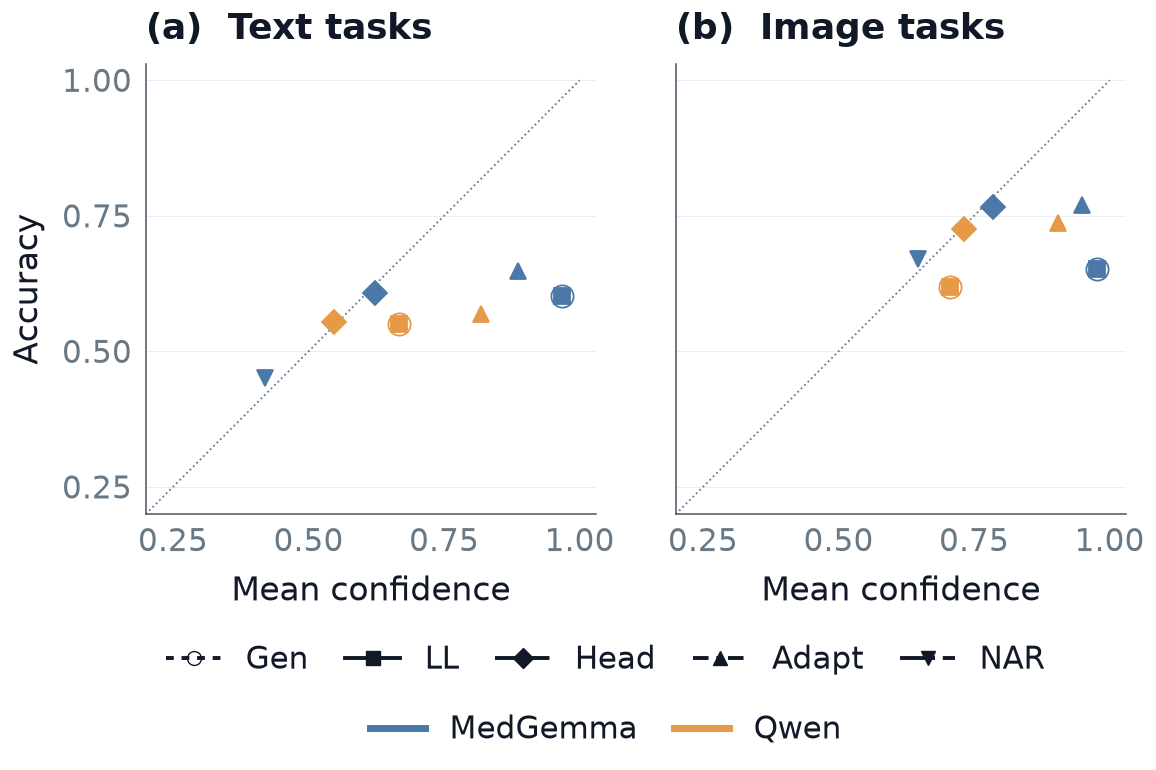

In [3]:
# Equal dataset weights in each modality, using all nine baseline result summaries.
summary_rows=[]
for method,table in SUMMARY_TABLES.items():
    for modality,datasets in [('Text',TEXT_SET),('Image',IMAGE_SET)]:
        group=table.loc[sorted(datasets)]
        summary_rows.append(dict(method=method,modality=modality,confidence=group.mean_confidence.mean(),accuracy=group.accuracy.mean()))
summary=pd.DataFrame(summary_rows)
fig,axes=panel_grid(1,2,legend=True,sharex=True,sharey=True)
for index,(ax,modality) in enumerate(zip(axes,['Text','Image'])):
    ax.plot([0,1],[0,1],linestyle=':',color=MUTED,linewidth=1.3)
    for row in summary[summary.modality==modality].itertuples():
        style=diagnostic_style(row.method);style['linestyle']='none';style['markersize']=16 if formulation(row.method)=='Gen' else 12
        ax.plot(row.confidence,row.accuracy,zorder=5 if formulation(row.method)=='Gen' else 3,**style)
    ax.set(xlim=(.2,1.03),ylim=(.2,1.03),xlabel='Mean confidence',xticks=[.25,.5,.75,1],yticks=[.25,.5,.75,1])
    panel_title(ax,index,f'{modality} tasks')
axes[0].set_ylabel('Accuracy')
diagnostic_legend(fig)
summary.to_csv(PAPER_FIGURES/'all_methods_confidence_accuracy.csv',index=False)
save(fig,'figure4_mean_confidence_accuracy')
plt.show()


## Selective risk across formulations
Each threshold retains confidence ties together. Curves equally average dataset risk and achieved coverage within a modality. Backbone-specific panels avoid overlapping nine curves in one panel.


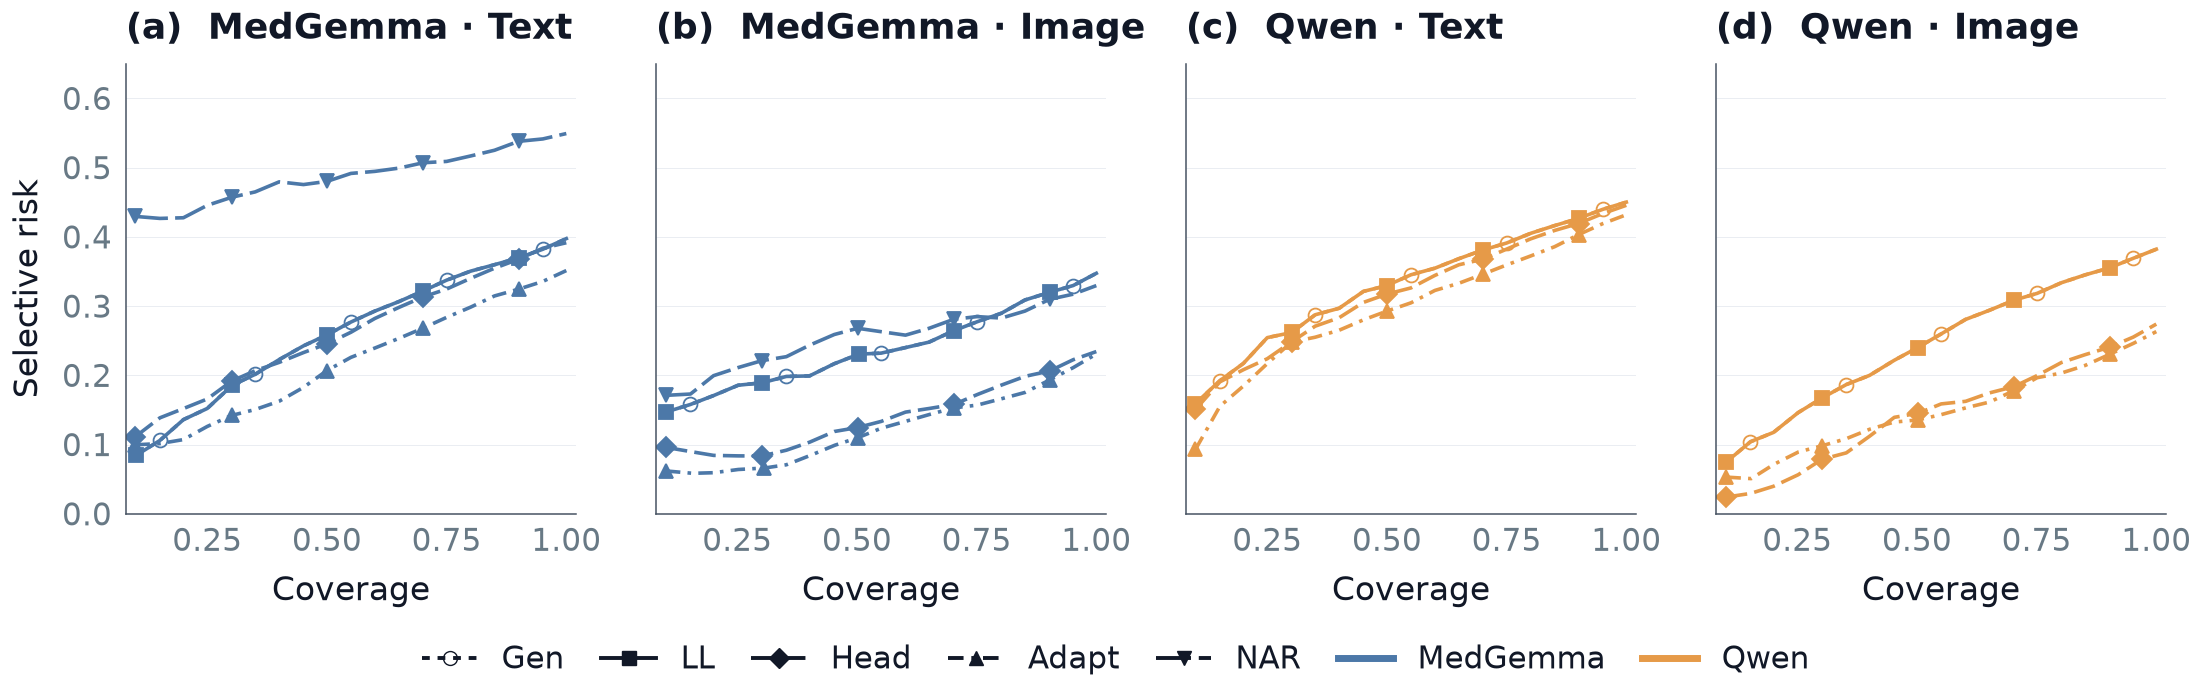

In [15]:
# Threshold-based routing, preserving confidence ties and equal dataset weights.
coverage_grid=np.linspace(.1,1,19)
selective_rows=[]
fig,axes=panel_grid(1,4,legend=True,sharey=True)
for index,(ax,family,modality,datasets) in enumerate(zip(axes,['MedGemma','MedGemma','Qwen','Qwen'],['Text','Image','Text','Image'],[TEXT_SET,IMAGE_SET,TEXT_SET,IMAGE_SET])):
    for method in [m for m in METHOD_ORDER if method_backbone(m)==family]:
        risks=[];coverages=[]
        for dataset in sorted(datasets):
            frame=METRICS[(METRICS.method==method)&(METRICS.dataset==dataset)]
            confidence=frame.confidence.to_numpy();correct=frame.correct.to_numpy()
            ds_risk=[];ds_cov=[]
            for target in coverage_grid:
                threshold=np.sort(confidence)[::-1][min(len(frame)-1,int(np.ceil(target*len(frame)))-1)]
                accepted=confidence>=threshold
                risk=1-correct[accepted].mean();coverage=accepted.mean()
                ds_risk.append(risk);ds_cov.append(coverage)
                selective_rows.append(dict(method=method,dataset=dataset,modality=modality,target=target,coverage=coverage,selective_risk=risk,n_retained=int(accepted.sum())))
            risks.append(ds_risk);coverages.append(ds_cov)
        style=diagnostic_style(method)
        ax.plot(np.mean(coverages,axis=0),np.mean(risks,axis=0),markevery=(1 if formulation(method)=='Gen' else 0,4),**style)
    panel_title(ax,index,f'{family} · {modality}')
    ax.set(xlim=(.08,1.02),ylim=(0,.65),xlabel='Coverage',xticks=[.25,.5,.75,1])
axes[0].set_ylabel('Selective risk')
selective_frame=pd.DataFrame(selective_rows)
# Fit all curves, including low-coverage extrema.
upper=min(1.02,max(.3,np.ceil(selective_frame.groupby(['method','modality','target']).selective_risk.mean().max()*10)/10+.05))
axes[0].set_ylim(0,upper)
diagnostic_legend(fig)
selective_frame.to_csv(PAPER_FIGURES/'four_formulation_selective_risk.csv',index=False)
save(fig,'figure5_four_formulation_selective_risk')
save(fig,'posthoc_risk_coverage_all_formulations')
plt.show()


## Routing and conformal policies
One row compares policies and modalities; color distinguishes the two backbones within each panel. Routing uses the baseline test confidences. MedGemma Head/Adapt conformal thresholds use held-out calibration records; NAR and Qwen Head/Adapt use verified saved conformal sets. LL appears in routing only. These panels pool examples within each modality.


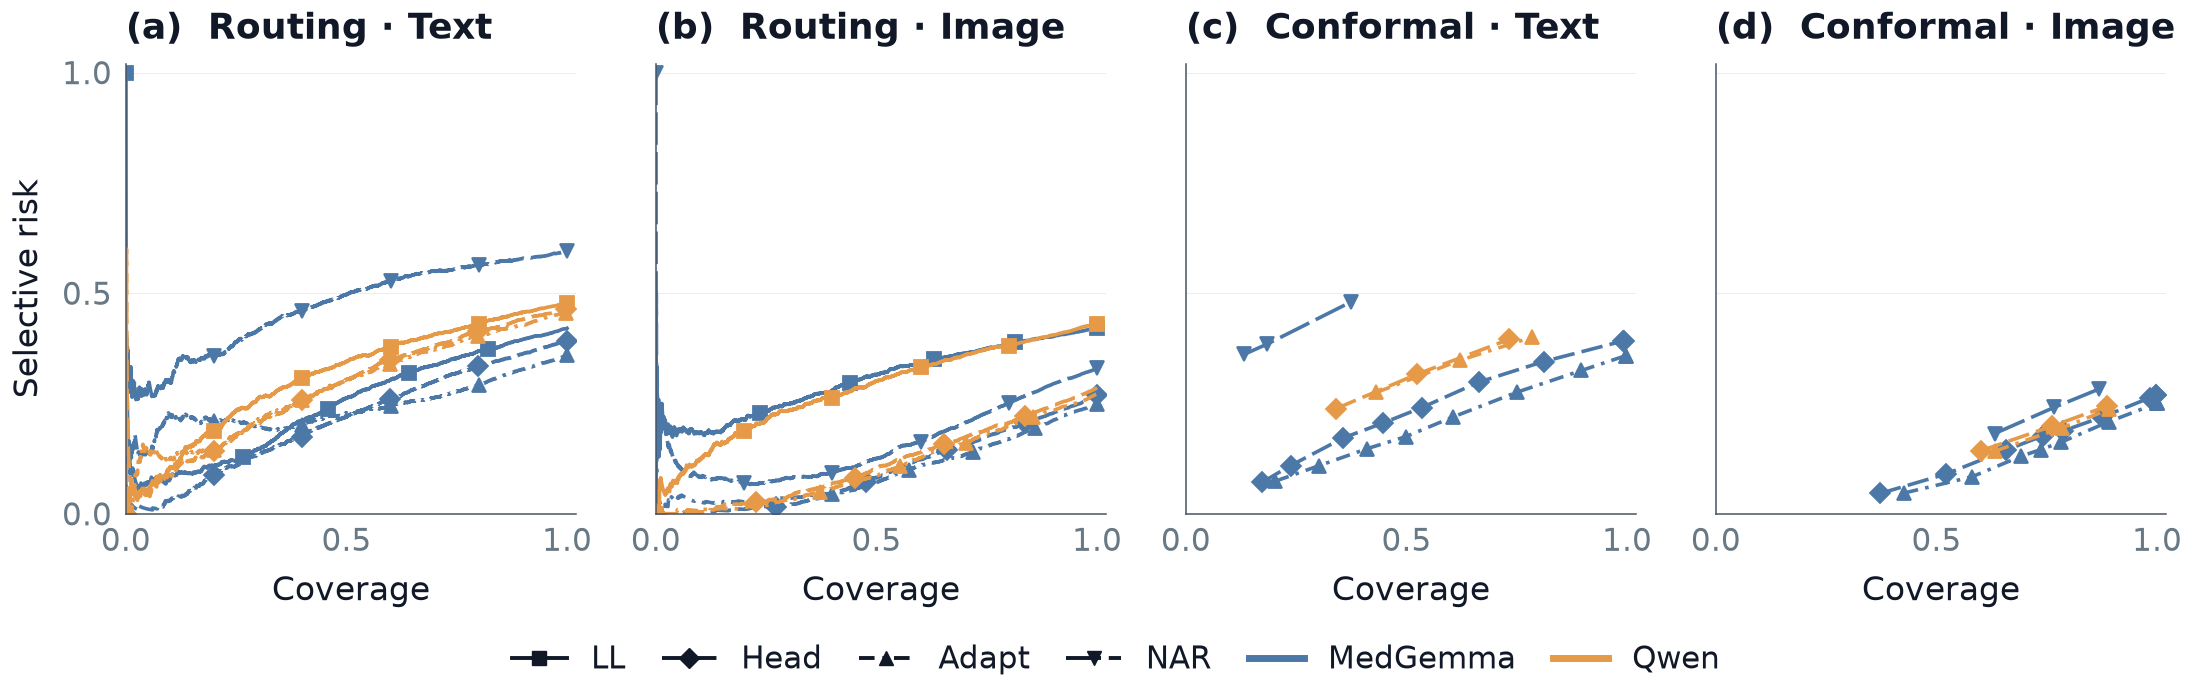

In [16]:
# Shared test cohorts; conformal thresholds come only from held-out calibration.
from collections import defaultdict
POLICY_METHODS=['MedGemma-LL','MedGemma-Head','MedGemma-Adapt','NAR','Qwen-LL','Qwen-Head','Qwen-Adapt']
CAL_FILES={'MedGemma-Head':'medgemma-head/calibration.predictions.jsonl',
           'MedGemma-Adapt':'medgemma-lora/calibration.predictions.jsonl'}
ALPHAS=[.02,.05,.1,.15,.2,.3,.4,.5,.6]
policy_rows=[]
for method in POLICY_METHODS:
    for modality,datasets in [('Text',TEXT_SET),('Image',IMAGE_SET)]:
        frame=METRICS[(METRICS.method==method)&METRICS.dataset.isin(datasets)]
        grouped=frame.assign(error=~frame.correct).groupby('confidence').agg(n=('correct','size'),errors=('error','sum')).sort_index(ascending=False).cumsum()
        for tau,row in grouped.iterrows():
            policy_rows.append(dict(method=method,modality=modality,policy='Routing',parameter=tau,n=len(frame),coverage=row.n/len(frame),risk=row.errors/row.n))
    if method in CAL_FILES:
        calibration=read_jsonl(RESULTS/CAL_FILES[method])
        keys=[(r.get('dataset',r.get('task')),str(r['id'])) for r in calibration]
        if len(keys)!=len(set(keys)) or set(keys)&reference_keys:
            raise ValueError(f'{method}: calibration/test overlap or duplicate IDs')
        scores=defaultdict(list)
        for row,key in zip(calibration,keys):
            p=row_probabilities(row);scores[key[0]].append(p.max()-p[int(row['label'])])
        assert set(scores)==set(DATASET_ORDER)
        test=RAW_ROWS[method]
        for alpha in ALPHAS:
            thresholds={}
            for dataset,values in scores.items():
                rank=int(np.ceil((len(values)+1)*(1-alpha)))
                thresholds[dataset]=np.inf if rank>len(values) else np.sort(values)[rank-1]
            counts={'Text':[0,0,0],'Image':[0,0,0]}
            for row in test:
                group='Text' if row['dataset'] in TEXT_SET else 'Image'
                p=row_probabilities(row);selected=np.flatnonzero(p.max()-p<=thresholds[row['dataset']])
                counts[group][0]+=1
                if len(selected)==1:
                    counts[group][1]+=1;counts[group][2]+=int(selected[0]!=int(row['label']))
            for modality,(n,accepted,errors) in counts.items():
                policy_rows.append(dict(method=method,modality=modality,policy='Conformal',parameter=alpha,n=n,coverage=accepted/n,risk=errors/accepted if accepted else np.nan))
    elif method in SAVED_CONFORMAL:
        for result in SAVED_CONFORMAL[method]['results']:
            frame=pd.DataFrame(result['rows'])
            for modality,datasets in [('Text',TEXT_SET),('Image',IMAGE_SET)]:
                group=frame[frame.dataset.isin(datasets)];selected=group[group.set_size==1]
                policy_rows.append(dict(method=method,modality=modality,policy='Conformal',parameter=result['alpha'],n=len(group),coverage=len(selected)/len(group),risk=1-selected.covered.mean()))
policy_frame=pd.DataFrame(policy_rows)
policy_frame.to_csv(PAPER_FIGURES/'posthoc_policy_risk_coverage.csv',index=False)
fig,axes=panel_grid(1,4,legend=True,sharex=True,sharey=True)
for index,(policy,modality) in enumerate([('Routing','Text'),('Routing','Image'),('Conformal','Text'),('Conformal','Image')]):
    ax=axes[index]
    for method in POLICY_METHODS:
        subset=policy_frame[(policy_frame.method==method)&(policy_frame.policy==policy)&(policy_frame.modality==modality)].dropna(subset=['risk']).sort_values('coverage')
        if subset.empty:continue
        ax.plot(subset.coverage,subset.risk,markevery=1 if policy=='Conformal' else max(1,len(subset)//5),**diagnostic_style(method))
    panel_title(ax,index,f'{policy} · {modality}')
    ax.set(xlim=(0,1.02),ylim=(0,1.02),xlabel='Coverage',xticks=[0,.5,1],yticks=[0,.5,1])
axes[0].set_ylabel('Selective risk')
diagnostic_legend(fig,forms=('LL','Head','Adapt','NAR'))
save(fig,'posthoc_risk_coverage_policies')
plt.show()


## TTA operating-point table
Accuracy (%) is followed by a smaller coverage (%) superscript for post-hoc columns; Base omits its constant 100% coverage. Both backbones share one horizontal layout. Only average rows are colored. One setting per formulation/policy maximizes dataset-balanced accepted accuracy among **saved settings with at least 70% overall dataset-balanced coverage**; ties favor greater coverage. If no saved setting qualifies, the highest-coverage point is reported explicitly in the selection CSV and in the coverage superscript. This overall constraint does not guarantee 70% in each dataset.

This is a descriptive selection on the exported test evaluations, not independent validation-based tuning. Parameters and all candidate points are exported to CSV. Base is the unrouted prediction from the routing ledger. LL routing and conformal exports use different saved prediction/scoring outputs; each policy is evaluated from its own ledger on matched IDs. No Gen conformal or Qwen NAR export exists. Average-row background color represents accepted accuracy, normalized within each backbone and row; all other cells are uncolored.


Saved /home/razaimam/Documents/Projects/Jevify/analysis/figures_new/tta_posthoc_heatmap.tex


,method,policy,parameter,accuracy,coverage,selection_status
0,MedGemma-LL,Routing,0.7,64.158356,96.689426,target_met
1,MedGemma-LL,Conformal,0.3,69.191382,78.414160,target_met
2,MedGemma-Head,Routing,0.5,77.540234,78.816708,target_met
3,MedGemma-Head,Conformal,0.2,77.722368,74.290107,target_met
4,MedGemma-Adapt,Routing,0.7,75.634542,88.603682,target_met
5,MedGemma-Adapt,Conformal,0.1,81.115706,72.407131,target_met
6,MedGemma-NAR,Routing,0.3,68.805577,66.958369,target_unmet
7,MedGemma-NAR,Conformal,0.3,65.904061,74.460355,target_met
8,Qwen-LL,Routing,0.5,63.712770,83.173419,target_met
9,Qwen-LL,Conformal,0.3,64.330691,71.014528,target_met


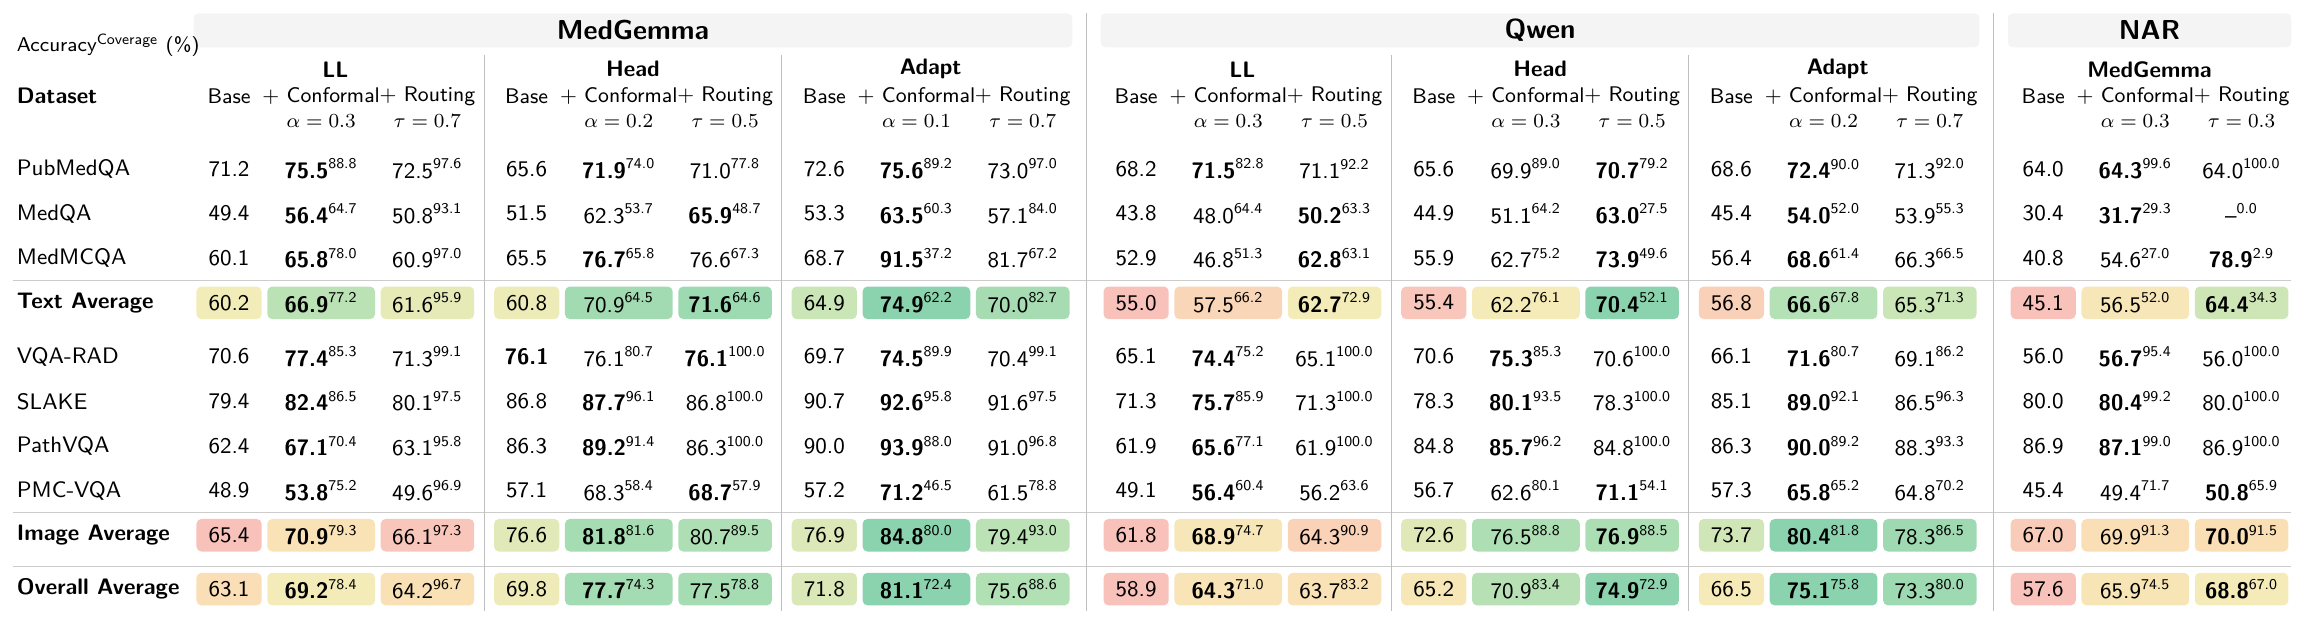

In [2]:
from tta_reporting_b import collect, table_tex
TTA_BUNDLE = collect(ROOT, floor=70.)
for key in ['table','selected','candidates','audit']:
    TTA_BUNDLE[key].to_csv(PAPER_FIGURES / f'tta_posthoc_{key}.csv',index=False)
TTA_TEX = PAPER_FIGURES / 'tta_posthoc_heatmap.tex'
TTA_TEX.write_text(table_tex(TTA_BUNDLE),encoding='utf-8')
print('Saved',TTA_TEX)
display(TTA_BUNDLE['selected'][['method','policy','parameter','accuracy','coverage','selection_status']])
# Render the same TikZ table when Tectonic is available.
import os,shutil,subprocess,tempfile
renderer=os.environ.get('TECTONIC') or shutil.which('tectonic')
if renderer:
    with tempfile.TemporaryDirectory(prefix='jev-tta-table-') as temp:
        wrapper=Path(temp)/'tta_posthoc_heatmap.tex'
        wrapper.write_text(r"\documentclass[border=5pt]{standalone}"+'\n'+r"\usepackage{tikz,xcolor}"+'\n'+r"\begin{document}"+'\n'+TTA_TEX.read_text()+'\n'+r"\end{document}")
        done=subprocess.run([renderer,str(wrapper)],capture_output=True,text=True)
        if done.returncode:raise RuntimeError(done.stdout+done.stderr)
        shutil.copy2(wrapper.with_suffix('.pdf'),TTA_TEX.with_suffix('.pdf'))
    subprocess.run(['pdftoppm','-r','180','-png','-singlefile',str(TTA_TEX.with_suffix('.pdf')),str(TTA_TEX.with_suffix(''))],check=True)
    from IPython.display import Image,display
    display(Image(filename=str(TTA_TEX.with_suffix('.png'))))


## Accuracy versus coverage: routing and conformal
Four panels in one row: MedGemma Text, MedGemma Image, Qwen Text, and Qwen Image. Both axes are percentages; the shared y-axis follows the displayed data range. Solid lines show routing and dashed lines show saved conformal operating points. The dotted vertical line marks 70% coverage. Gen has routing only; NAR is available only for MedGemma. Groups equally weight datasets. LL uses each policy’s saved scorer.


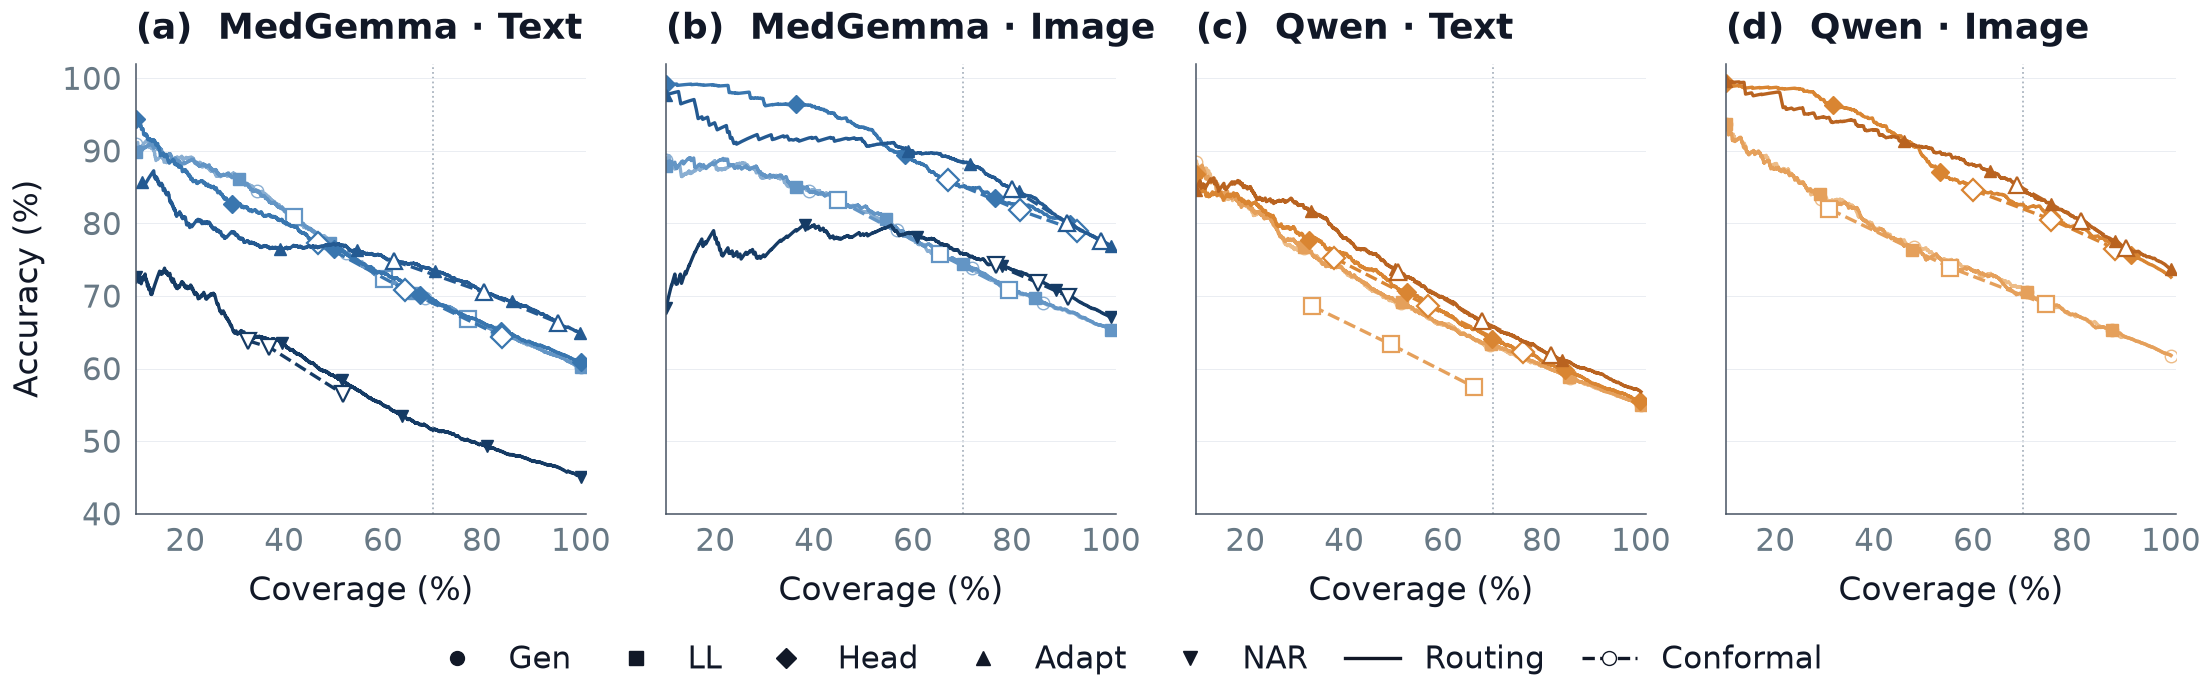

In [2]:
from tta_reporting_b import summarize as summarize_tta
FORM_COLORS = {'MedGemma':['#89AED2','#6395C5','#3976AF','#245A92','#153B65'],
               'Qwen':['#EDBC87','#E5A05B','#D98532','#B96320','#874416']}
forms=['Gen','LL','Head','Adapt','NAR']
shapes=['o','s','D','^','v']
fig,axes=panel_grid(1,4,legend=True,sharex=True,sharey=True,top=1.3)
curve_rows=[]
for index,(ax,family,modality,datasets) in enumerate(zip(axes,['MedGemma','MedGemma','Qwen','Qwen'],['Text','Image','Text','Image'],[TEXT_SET,IMAGE_SET,TEXT_SET,IMAGE_SET])):
    ax.axvline(70,color='#AAB4BF',linestyle=':',linewidth=1.3,zorder=0)
    for j,form in enumerate(forms):
        method=family+'-'+form
        if method not in TTA_BUNDLE['routing']:continue
        frame=TTA_BUNDLE['routing'][method]
        frame=frame[frame.dataset.isin(datasets)].copy()
        frame['weight']=1/frame.groupby('dataset').id.transform('size')
        frame['correct_weight']=(frame.prediction==frame.label)*frame.weight
        groups=frame.groupby('score')[['weight','correct_weight']].sum().sort_index(ascending=False).cumsum()
        coverage=100*groups.weight/frame.weight.sum()
        accuracy=100*groups.correct_weight/groups.weight
        show=coverage>=10
        ax.plot(coverage[show],accuracy[show],color=FORM_COLORS[family][j],marker=shapes[j],
                markevery=max(1,int(show.sum())//5),markersize=9,linewidth=2.4,
                markerfacecolor='none' if form=='Gen' else FORM_COLORS[family][j],linestyle='-')
        for tau,cov,acc in zip(groups.index,coverage,accuracy):
            curve_rows.append(dict(method=method,modality=modality,policy='Routing',parameter=tau,coverage=cov,accuracy=acc))
        points=[]
        for alpha,cf in TTA_BUNDLE['conformal'].get(method,[]):
            values=summarize_tta(cf,cf.set_size==1,cf.covered,datasets)
            points.append((values['coverage'],values['accuracy']))
            curve_rows.append(dict(method=method,modality=modality,policy='Conformal',parameter=alpha,**values))
        if points:
            points=np.asarray(sorted(points));points=points[points[:,0]>=10]
            if len(points):ax.plot(points[:,0],points[:,1],color=FORM_COLORS[family][j],marker=shapes[j],
                    markerfacecolor='white',markeredgewidth=1.6,markersize=11,linestyle='--',linewidth=2.4)
    panel_title(ax,index,f'{family} · {modality}')
    ax.set(xlim=(10,101),xticks=[20,40,60,80,100],xlabel='Coverage (%)')
# Shared data-driven y limits, as in the previous four-panel version.
visible=pd.DataFrame(curve_rows)
visible=visible[(visible.coverage>=10)&visible.accuracy.notna()]
low,high=visible.accuracy.min(),visible.accuracy.max()
padding=max(2.,.06*(high-low))
ymin=max(0.,5*np.floor((low-padding)/5))
ymax=min(102.,5*np.ceil((high+padding)/5))
axes[0].set_ylim(ymin,ymax)
axes[0].set_yticks(np.arange(10*np.ceil(ymin/10),min(100,ymax)+.01,10))
axes[0].set_ylabel('Accuracy (%)')
handles=[Line2D([],[],color=INK,marker=m,linestyle='none',markersize=10) for m in shapes]
handles += [Line2D([],[],color=INK,linestyle='-',linewidth=2.4),Line2D([],[],color=INK,linestyle='--',marker='o',markerfacecolor='white',linewidth=2.4)]
figure_legend(fig,handles,forms+['Routing','Conformal'],ncols=7)
pd.DataFrame(curve_rows).to_csv(PAPER_FIGURES/'tta_accuracy_coverage_data.csv',index=False)
save(fig,'tta_accuracy_coverage')
plt.show()
